# T1 - Aprendizado Não Supervisionado - Dataset Regenera

Aprendizado de Máquina - Prof. Me. Otávio Parraga - PUCRS

Grupo: Dhara Hadi, Júlia Bettiol, Gabriel Ottonelli, Matheus Azevedo, Samuel Morales e Thomaz Szeckir

Neste trabalho buscamos estrutura escondida na coleção de microrganismos marinhos do Banco Regenera, sem nenhum rótulo guiando o aprendizado. 

-Na Tarefa A, de agrupamento, escolhemos o K-Means e o agrupamento hierárquico aglomerativo com ligação de Ward. 

-Na Tarefa B, de redução de dimensionalidade, escolhemos a PCA como estratégia linear e o UMAP como estratégia não linear.

Organização:

0. Configuração
1. Pré-processamento (Exploração, limpeza e transformações)
2. Tarefa A - Agrupamento
3. Tarefa B - Redução de dimensionalidade
4. Análise crítica (Sensibilidade ao pré-processamento e conclusão)

## 0. Configuração

A célula abaixo importa as bibliotecas que usamos ao longo do trabalho e fixa a semente aleatória em 42, para que todos os resultados possam ser reproduzidos.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency  # scipy: teste de independencia, hierarquico e comparacao de projecoes
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial import procrustes

from sklearn.preprocessing import StandardScaler, RobustScaler  # pre-processamento, agrupamento e reducao de dimensionalidade
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import trustworthiness

from sklearn.metrics import (  # metricas internas e externas de agrupamento
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_completeness_v_measure,
)

from sklearn.model_selection import StratifiedKFold, cross_val_score  # classificadores para medir a utilidade da reducao
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline

import umap  # reducao nao linear

SEED = 42  # semente e caminho do arquivo
np.random.seed(SEED)
DATA_PATH = "Data_REG.tsv"

pd.set_option("display.max_columns", 50)  # opcoes de exibicao
sns.set_theme(style="whitegrid")

## 1. Pré-processamento

Aqui fazemos a exploração do arquivo, a limpeza e as transformações antes de rodar qualquer modelo.

### 1.1 Exploração

#### Leitura e inventário

Lemos tudo como texto (`dtype=str`) para o pandas não transformar em NaN, sem avisar, os valores que ele não conseguisse converter. Assim a gente consegue ver a sujeira do arquivo.

In [2]:
df_raw = pd.read_csv(DATA_PATH, sep="\t", dtype=str)  # tudo como texto
print(df_raw.shape)
df_raw.head()

(506, 33)


,n°,GRAM,Cor,Cores,Borda,Textura,Forma,Brilho,Muco,Relevo,Atividade 01,Atividade 02,Atividade 03,Atividade 04,Atividade 05,Atividade 06,Atividade 07,Atividade 08,Atividade 09,Atividade 10,Atividade 11,Atividade 12,Atividade 13,Atividade 14,Atividade 15,Atividade 16,Atividade 17,Atividade 18,Atividade 19,Atividade 20,Atividade 21,Atividade 22,Atividade 23
0,1413,Negativo,1,2,0,1,1,2,0,1,0,0,Negativo,Negativo,1.2,0,0,-0.01,0.76,0.54,0.74,0.06,1,0,0,Positivo,1,1,3,1,3,0,2.767
1,1414,Positivo,1,2,0,1,4 & 1,2,0,0,0,2.33,Negativo,Negativo,1.2,-0.01,0.13,-0.04,0.28,0.1,0.09,0.04,0,2.8,3,Positivo,3,3,2,3,3,0,12.678
2,1415,Positivo,1,2,0,2 & 1,4 & 1,2,0,0,0,3.5,Negativo,Negativo,1.38,0,0.43,0.01,0.12,0.26,0.27,0.14,0,2,2.5,Positivo,3,3,3,3,3,3,6.87
3,1417,Negativo,1,2,0,1,1,2,0,1,0,0,Negativo,Negativo,1.25,0.67,0.11,0.03,0.99,0.67,0.24,0.11,2,0,0,Positivo,0,0,0,0,1,0,2.728
4,1418,Positivo,1,3,0,1,4 & 1,2,0,0,0,1.75,Negativo,Negativo,1.2,0,0.1,-0.02,0.24,0.26,0.09,0.17,0,2.33,1.2,Positivo,2,3,0,3,3,3,11.353


In [3]:
ID = "n°"
MORPH = ["Cor", "Cores", "Borda", "Textura", "Forma", "Brilho", "Muco", "Relevo"]
ACTS = [c for c in df_raw.columns if c.startswith("Atividade")]


def A(n):
    return f"Atividade {n:02d}"


BIN_ACTS = [A(n) for n in [1, 3, 4, 16]]
ORD_ACTS = [A(n) for n in [13, 17, 18, 19, 20, 21, 22]]
CONT_ACTS = [A(n) for n in [2, 5, 6, 7, 8, 9, 10, 11, 12, 14, 15, 23]]

assert sorted(BIN_ACTS + ORD_ACTS + CONT_ACTS) == sorted(ACTS)  # as tres listas cobrem as 23 atividades

In [4]:
tipo = {ID: "id", "GRAM": "referência"}
for c in MORPH:
    tipo[c] = "morfologia"
for c in BIN_ACTS:
    tipo[c] = "binária"
for c in ORD_ACTS:
    tipo[c] = "ordinal"
for c in CONT_ACTS:
    tipo[c] = "contínua"

inventario = pd.DataFrame(index=df_raw.columns)
inventario["tipo"] = pd.Series(tipo)
inventario["distintos"] = df_raw.nunique()
inventario["ausentes"] = df_raw.isna().sum()
inventario["exemplos"] = [list(df_raw[c].dropna().unique()[:6]) for c in df_raw.columns]
inventario

,tipo,distintos,ausentes,exemplos
n°,id,505,0,"[1413, 1414, 1415, 1417, 1418, 1419]"
GRAM,referência,7,0,"[Negativo, Positivo, Levedura, POSITIVO, Variá..."
Cor,morfologia,6,1,"[1, 2, 7, 3 & 5, 3, 6]"
Cores,morfologia,29,1,"[2, 3, 7, 5, 6, 5 & 3]"
Borda,morfologia,3,2,"[0, 2, 1]"
Textura,morfologia,4,2,"[1, 2 & 1, 2, 1 & 2]"
Forma,morfologia,7,3,"[1, 4 & 1, 4, 6, 4 & 2, 2]"
Brilho,morfologia,6,3,"[2, 1 & 2, 1, 4, 2 & 1, 0]"
Muco,morfologia,3,3,"[0, 1, 2]"
Relevo,morfologia,2,4,"[1, 0]"


São 506 linhas e 33 colunas, mas o `n°` só tem 505 valores distintos, então tem um isolado repetido.

Para classificar as atividades olhamos os valores de cada uma. Se só tem dois valores, é binária. Se só tem os inteiros de 0 a 3, é ordinal, porque parece um nível de intensidade. Se tem decimais e muitos valores, é contínua. Ficaram 4 binárias, 7 ordinais e 12 contínuas. Os ausentes das atividades estão na 20 (27), na 21 (17) e na 23 (3).

#### Valores das categóricas

In [5]:
for c in ["GRAM"] + MORPH:
    print(c, df_raw[c].value_counts(dropna=False).to_dict())

GRAM {'Negativo': 244, 'Positivo': 218, 'Levedura': 40, 'POSITIVO': 1, 'Variável': 1, 'Levedura? não ': 1, 'Positiva': 1}
Cor {'1': 432, '2': 68, '3': 2, nan: 1, '7': 1, '3 & 5': 1, '6': 1}
Cores {'3': 199, '2': 141, '6': 34, '4': 30, '5': 19, '2 & 1': 16, '2 & 3': 9, '3 & 4': 9, '1': 7, '3 & 1': 7, '6 & 2': 4, '4 & 2': 4, '6 & 1': 3, '3 & 6': 3, '0': 3, '3 & 2': 2, '5 & 2': 2, '7': 2, '2 & 5': 1, '1 & 6': 1, '7 & 1': 1, '6 & 4': 1, '4 & 5': 1, '7 & 2': 1, '20': 1, '1 & 2': 1, 'OBS': 1, nan: 1, '5 & 3': 1, '6;2': 1}
Borda {'0': 395, '2': 63, '1': 46, nan: 2}
Textura {'1': 327, '2': 154, '1 & 2': 16, '2 & 1': 7, nan: 2}
Forma {'1': 355, '4': 93, '4 & 1': 37, '4 & 2': 8, '2': 6, nan: 3, '6': 2, '1 & 2': 2}
Brilho {'2': 372, '1': 92, '1 & 2': 28, '2 & 1': 8, nan: 3, '0': 2, '4': 1}
Muco {'0': 369, '1': 133, nan: 3, '2': 1}
Relevo {'0': 307, '1': 195, nan: 4}


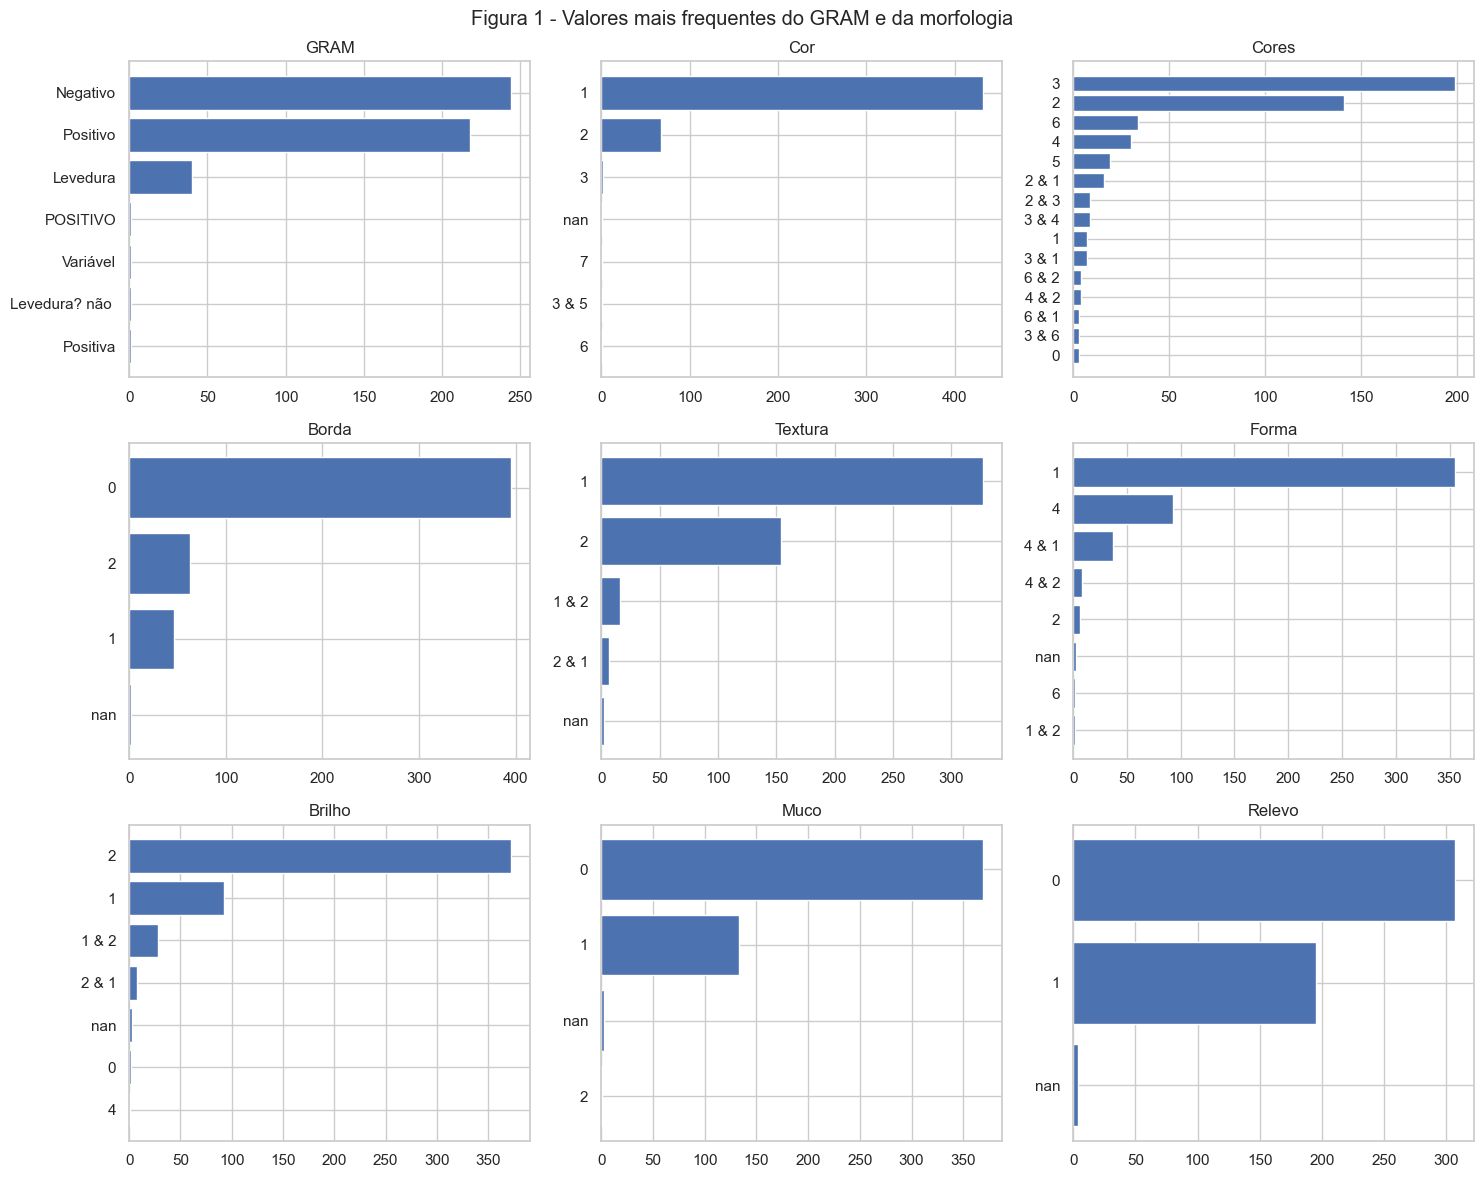

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, c in zip(axes.flat, ["GRAM"] + MORPH):
    vc = df_raw[c].value_counts(dropna=False).head(15)
    ax.barh([str(v) for v in vc.index], vc.values)  # str para o nan aparecer como rotulo
    ax.invert_yaxis()  # mais frequente em cima
    ax.set_title(c)
fig.suptitle("Figura 1 - Valores mais frequentes do GRAM e da morfologia")
plt.tight_layout()
plt.show()

Nas contagens e na Figura 1 já aparecem vários problemas. No GRAM tem "POSITIVO", "Positiva", "Variável" e "Levedura? não " (com espaço no final), cada um numa linha só. Na morfologia tem célula com dois códigos, às vezes em ordem trocada (em Brilho, "1 & 2" aparece 28 vezes e "2 & 1" aparece 8), e a coluna Cores tem um "OBS", um "6;2" e um "20". Também tem códigos que aparecem uma ou duas vezes, como o 7 em Cor e o 2 em Muco, e não dá para saber se são erro de digitação ou uma categoria rara.

Fora isso, em quase todas as colunas um ou dois valores dominam. Em Cor, por exemplo, o código 1 tem 432 dos 506 isolados.

#### Distribuições das atividades

Para fazer os gráficos, convertemos as atividades para número de forma provisória (Positivo = 1, Negativo = 0) e conferimos o que não era número.

In [7]:
acts_txt = df_raw[ACTS].replace({"Positivo": "1", "Negativo": "0"})
acts_num = acts_txt.apply(pd.to_numeric, errors="coerce")  # provisorio, so para explorar
acts_txt[acts_num.isna() & acts_txt.notna()].stack()  # valores que nao eram numero

275  Atividade 23    #NÚM!
dtype: object

In [8]:
tab = acts_num[CONT_ACTS].describe().T
tab["assimetria"] = acts_num[CONT_ACTS].skew()
tab["% zeros"] = (acts_num[CONT_ACTS] == 0).mean() * 100
tab["negativos"] = (acts_num[CONT_ACTS] < 0).sum()
tab.round(2)

,count,mean,std,min,25%,50%,75%,max,assimetria,% zeros,negativos
Atividade 02,506.0,0.95,1.25,0.00,0.00,0.00,1.98,5.83,0.96,58.50,0
Atividade 05,506.0,0.71,0.68,0.00,0.00,1.00,1.25,3.60,0.43,44.47,0
Atividade 06,506.0,0.09,0.19,-0.06,0.00,0.01,0.02,0.81,2.14,34.39,34
Atividade 07,506.0,0.12,0.13,-0.08,0.04,0.10,0.16,0.81,2.24,3.95,34
Atividade 08,506.0,0.02,0.04,-0.19,0.00,0.01,0.04,0.16,-0.05,14.23,125
Atividade 09,506.0,0.72,0.32,0.00,0.47,0.75,0.98,1.51,-0.23,0.59,0
Atividade 10,506.0,0.44,0.20,0.00,0.30,0.42,0.58,1.08,0.29,0.79,0
Atividade 11,506.0,0.27,0.14,0.00,0.17,0.24,0.36,0.74,0.77,0.20,0
Atividade 12,506.0,0.19,0.12,-0.08,0.11,0.18,0.26,0.70,0.96,0.20,1
Atividade 14,506.0,0.96,1.69,0.00,0.00,0.00,1.48,15.50,2.88,63.44,0


O único valor que não era número foi um "#NÚM!" na Atividade 23, que é erro de fórmula do Excel. Por enquanto ele virou NaN.

Na tabela dá para ver que as escalas são bem diferentes: a Atividade 23 vai até 577,89, e várias outras não passam de 1, então vamos precisar padronizar. Cinco colunas têm assimetria acima de 2 (06, 07, 14, 15 e 23), e algumas têm muito zero, como a 14, com 63,44%. Também tem negativos pequenos, principalmente na 08 (125), que parecem ruído de medida perto de zero.

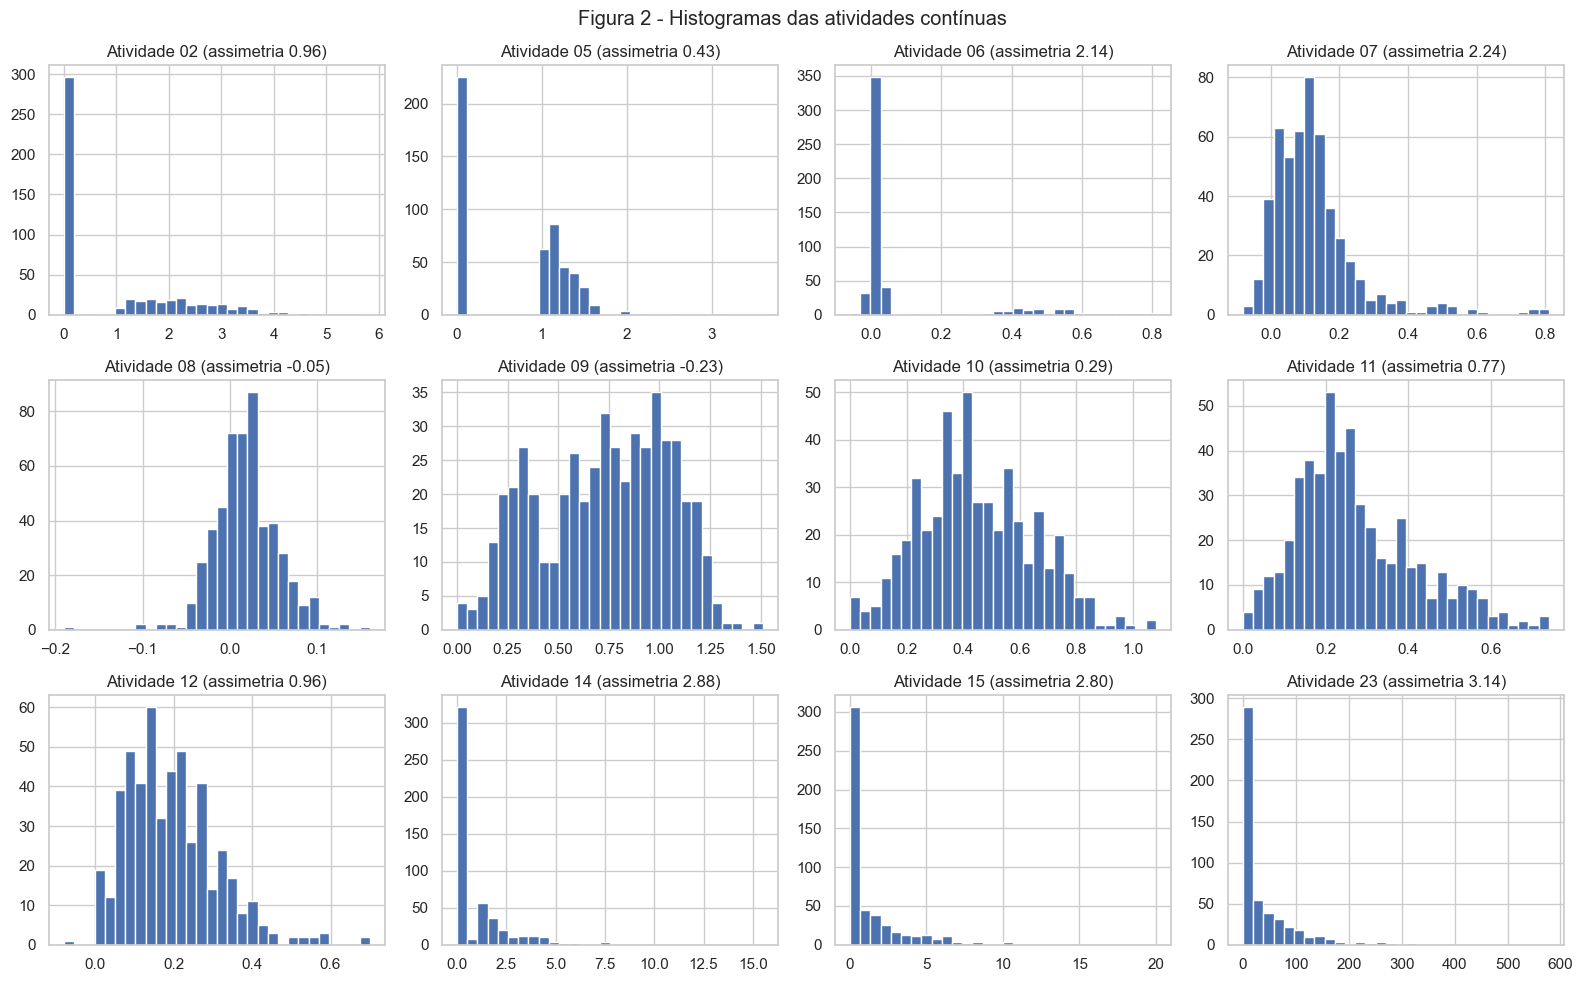

In [9]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, c in zip(axes.flat, CONT_ACTS):
    ax.hist(acts_num[c].dropna(), bins=30)
    ax.set_title(f"{c} (assimetria {acts_num[c].skew():.2f})")
fig.suptitle("Figura 2 - Histogramas das atividades contínuas")
plt.tight_layout()
plt.show()

Na Figura 2, as Atividades 02, 14, 15 e 23 têm um pico grande perto do zero e uma cauda longa para a direita. A 05 e a 06 são curiosas: têm o pico no zero e depois um segundo grupo separado, como se o isolado ou não respondesse ou respondesse com uma intensidade típica. Já a 08, a 09 e a 10 são mais simétricas.

Pelo que vimos, as candidatas ao log são as cinco com assimetria acima de 2 (06, 07, 14, 15 e 23).

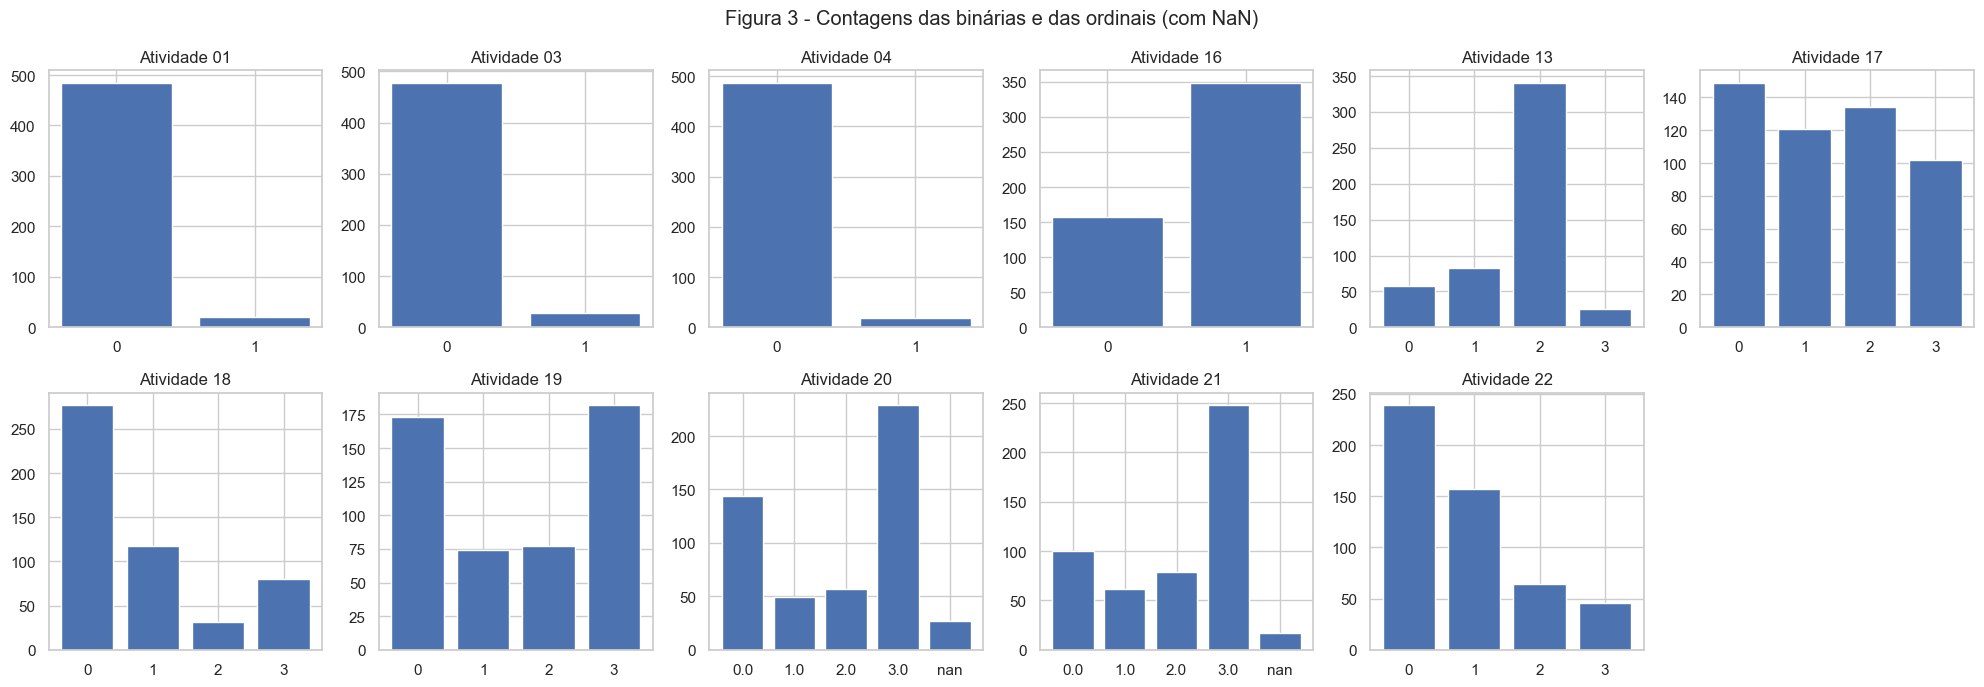

In [10]:
fig, axes = plt.subplots(2, 6, figsize=(20, 7))
for ax, c in zip(axes.flat, BIN_ACTS + ORD_ACTS):
    vc = acts_num[c].value_counts(dropna=False).sort_index()
    ax.bar([str(v) for v in vc.index], vc.values)
    ax.set_title(c)
axes.flat[-1].axis("off")  # sobra um quadro
fig.suptitle("Figura 3 - Contagens das binárias e das ordinais (com NaN)")
plt.tight_layout()
plt.show()

Na Figura 3, três binárias quase nunca dão positivo: a 01 tem 21 positivos, a 03 tem 28 e a 04 tem 19. Isso preocupa porque, se padronizarmos, esses poucos positivos viram valores bem altos e pesam muito. A 16 é o contrário, com 349 positivos.

Nas ordinais cada atividade tem um formato: a 13 concentra quase tudo no nível 2, a 19 tem forma de U e a 17 é bem equilibrada. Os únicos ausentes estão na 20 e na 21.

#### Relações entre as atividades

Usamos Spearman em vez de Pearson porque temos binárias, ordinais e contínuas com cauda longa na mesma matriz. O Spearman usa a ordem dos valores, então não precisa de relação linear e não se deixa levar pelos valores extremos.

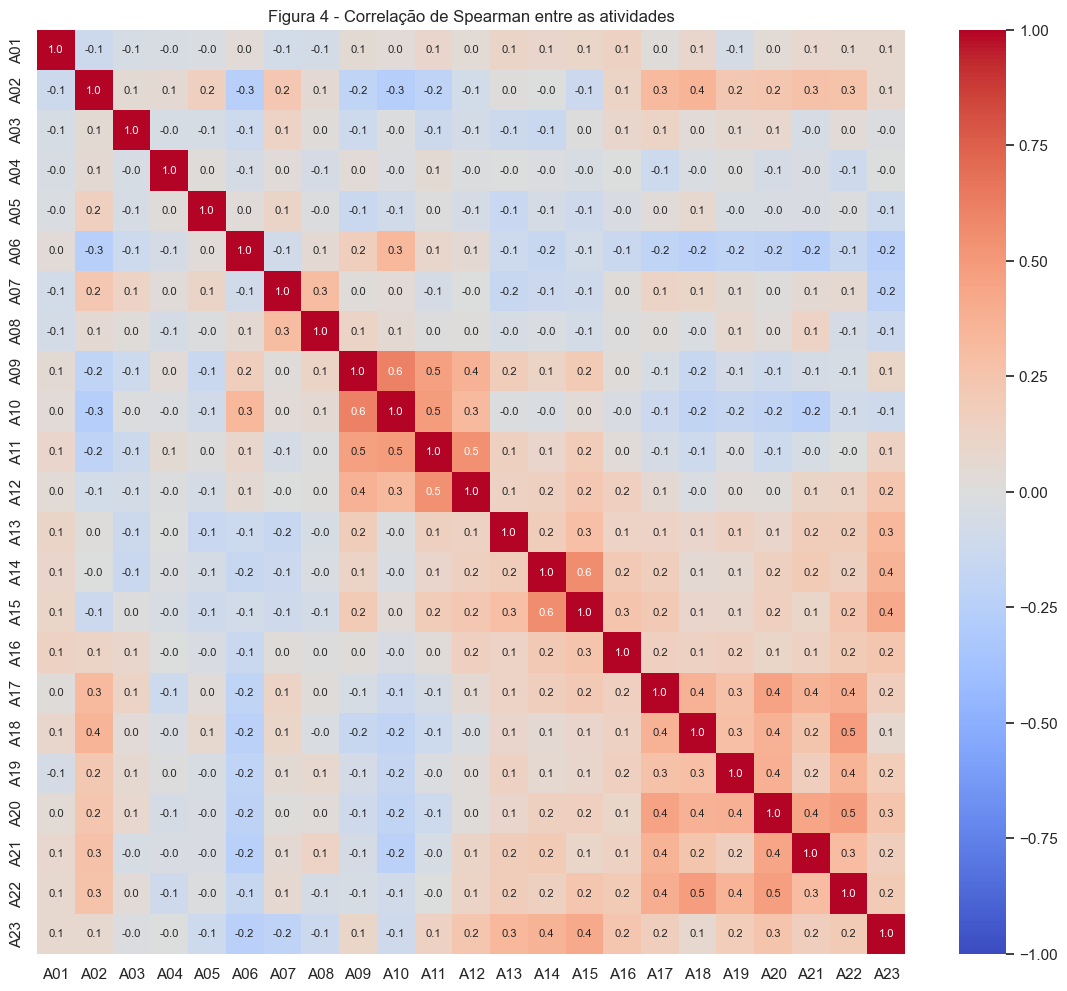

Atividade 09  Atividade 10    0.610
Atividade 14  Atividade 15    0.562
Atividade 11  Atividade 12    0.541
Atividade 10  Atividade 11    0.487
Atividade 18  Atividade 22    0.482
Atividade 20  Atividade 22    0.476
Atividade 09  Atividade 11    0.464
Atividade 17  Atividade 20    0.446
Atividade 20  Atividade 21    0.439
Atividade 15  Atividade 23    0.417
Atividade 17  Atividade 22    0.395
Atividade 19  Atividade 20    0.382
dtype: float64

In [11]:
corr = acts_num.corr(method="spearman")
curtos = ["A" + c[-2:] for c in ACTS]

plt.figure(figsize=(14, 12))
sns.heatmap(corr, annot=True, fmt=".1f", cmap="coolwarm", vmin=-1, vmax=1,
            xticklabels=curtos, yticklabels=curtos, annot_kws={"size": 8})
plt.title("Figura 4 - Correlação de Spearman entre as atividades")
plt.show()

pares = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()  # cada par so uma vez
pares.reindex(pares.abs().sort_values(ascending=False).index).head(12).round(3)

Na Figura 4 a maior parte da matriz fica perto de zero, e nenhum par passa de 0,7, então nenhuma atividade é cópia de outra. As Atividades 01, 03, 04 e 05 quase não se relacionam com nenhuma outra.

Os pares mais correlacionados formam três blocos: as Atividades 09, 10, 11 e 12 (o par mais forte é 09 e 10, com 0,61), as ordinais de 17 a 22, que aparecem em seis dos doze pares, e as de cauda longa 14, 15 e 23 (14 e 15 com 0,562). Isso indica que as 23 atividades têm bem menos de 23 "direções" independentes, o que deve ajudar a PCA. Como os ensaios são anonimizados, não dá para saber o que cada bloco mede.

### 1.2 Limpeza

Todas as correções vão para um log, com o problema, a coluna, os valores, quantas linhas e o que fizemos. Trabalhamos numa cópia, para não mexer no arquivo cru.

In [12]:
log = []


def registra(problema, coluna, valores, n, tratamento):
    log.append({"problema": problema, "coluna": coluna, "valores": valores, "n": n, "tratamento": tratamento})


df = df_raw.copy()

for c in df.columns:  # a) espacos sobrando
    sujos = df[c].notna() & (df[c] != df[c].str.strip())
    if sujos.any():
        registra("espaço sobrando", c, list(df.loc[sujos, c].unique()), sujos.sum(), "strip()")
        df[c] = df[c].str.strip()

errados = df["GRAM"].isin(["POSITIVO", "Positiva"])  # b) gram
registra("grafia diferente", "GRAM", list(df.loc[errados, "GRAM"].unique()), errados.sum(), "virou Positivo")
df.loc[errados, "GRAM"] = "Positivo"
fora = ~df["GRAM"].isin(["Positivo", "Negativo", "Levedura"])
registra("categoria fora do esperado", "GRAM", list(df.loc[fora, "GRAM"].unique()), fora.sum(), "NaN (linha mantida, só fica fora das métricas externas)")
df.loc[fora, "GRAM"] = np.nan

rep = df[ID] == "1551"  # c) id repetido: mesma morfologia, atividades diferentes
df.loc[rep, ID] = ["1551_a", "1551_b"]
registra("ID repetido", ID, ["1551"], rep.sum(), "mantidas como 1551_a e 1551_b (a 4.1 testa remover)")

for c in ACTS:  # d) residuo de formula do excel
    formula = df[c].str.startswith("#", na=False)
    if formula.any():
        registra("resíduo de fórmula", c, list(df.loc[formula, c].unique()), formula.sum(), "NaN")
        df.loc[formula, c] = np.nan

for c in BIN_ACTS:  # e) binarias escritas por extenso
    if df[c].isin(["Positivo", "Negativo"]).any():
        registra("binária escrita por extenso", c, ["Positivo", "Negativo"], len(df), "Positivo = 1, Negativo = 0")
        df[c] = df[c].replace({"Positivo": "1", "Negativo": "0"})

df[ACTS] = df[ACTS].apply(pd.to_numeric)  # sem coerce: se sobrasse texto daria erro

In [13]:
DOMINIO = {"Cor": (1, 7), "Cores": (0, 7), "Borda": (0, 2), "Textura": (1, 2),  # f) morfologia: menor e maior codigo valido
           "Forma": (1, 6), "Brilho": (1, 2), "Muco": (0, 1), "Relevo": (0, 1)}


def le_codigos(valor, col):
    if pd.isna(valor):
        return np.nan, None
    partes = [p.strip() for p in valor.replace(";", "&").split("&")]
    if not all(p.isdigit() for p in partes):
        return np.nan, "texto não numérico"
    codigos = tuple(sorted(set(int(p) for p in partes)))  # ordenado: 2 & 1 e 1 & 2 viram (1, 2)
    menor, maior = DOMINIO[col]
    if any(c < menor or c > maior for c in codigos):
        return np.nan, "código fora do domínio"
    return codigos, None


for col in MORPH:
    pv = df[col].str.contains(";", na=False)
    if pv.any():
        registra("separador ;", col, list(df.loc[pv, col].unique()), pv.sum(), "trocado por &")

    novos, ruins = [], {}
    for v in df[col]:
        cod, motivo = le_codigos(v, col)
        novos.append(cod)
        if motivo:
            ruins.setdefault(motivo, []).append(v)
    for motivo, vals in ruins.items():
        registra(motivo, col, sorted(set(vals)), len(vals), "NaN")
    df[col] = pd.Series(novos, index=df.index, dtype=object)

    multi = df[col].apply(lambda t: isinstance(t, tuple) and len(t) > 1)
    if multi.any():
        registra("mais de um código", col, list(df_raw.loc[multi, col].unique()), multi.sum(), "tupla ordenada")

In [14]:
for col in MORPH:  # g) ausentes da morfologia: moda
    n = df[col].isna().sum()
    if n > 0:
        moda = df[col].dropna().value_counts().index[0]
        registra("ausente", col, [], n, "moda " + "&".join(str(c) for c in moda))
        df[col] = df[col].apply(lambda t: t if isinstance(t, tuple) else moda)

for c in ACTS:  # continuas: mediana; binarias e ordinais: moda
    n = df[c].isna().sum()
    if n > 0:
        if c in CONT_ACTS:
            valor, nome = df[c].median(), "mediana"
        else:
            valor, nome = df[c].mode()[0], "moda"
        registra("ausente", c, [], n, f"{nome} {valor:g}")
        df[c] = df[c].fillna(valor)

for c in CONT_ACTS:  # h) negativos: so registra, ficam como estao
    neg = df[c] < 0
    if neg.any():
        registra("valor negativo", c, [df[c].min()], neg.sum(), "mantido (ruído perto de zero, o log1p aceita > -1)")

log_df = pd.DataFrame(log)
log_df

,problema,coluna,valores,n,tratamento
0,espaço sobrando,GRAM,[Levedura? não ],1,strip()
1,grafia diferente,GRAM,"[POSITIVO, Positiva]",2,virou Positivo
2,categoria fora do esperado,GRAM,"[Variável, Levedura? não]",2,"NaN (linha mantida, só fica fora das métricas ..."
3,ID repetido,n°,[1551],2,mantidas como 1551_a e 1551_b (a 4.1 testa rem...
4,resíduo de fórmula,Atividade 23,[#NÚM!],1,NaN
5,binária escrita por extenso,Atividade 03,"[Positivo, Negativo]",506,"Positivo = 1, Negativo = 0"
6,binária escrita por extenso,Atividade 04,"[Positivo, Negativo]",506,"Positivo = 1, Negativo = 0"
7,binária escrita por extenso,Atividade 16,"[Positivo, Negativo]",506,"Positivo = 1, Negativo = 0"
8,mais de um código,Cor,[3 & 5],1,tupla ordenada
9,separador ;,Cores,[6;2],1,trocado por &


In [15]:
df_clean = df.copy()
print(df_clean.shape)
print("ausentes que sobraram:", df_clean.isna().sum().sum())
print(df_clean["GRAM"].value_counts(dropna=False))

(506, 33)
ausentes que sobraram: 2
GRAM
Negativo    244
Positivo    220
Levedura     40
NaN           2
Name: count, dtype: int64


O log ficou com 33 registros. Resumindo o que decidimos: as grafias do GRAM foram corrigidas, e "Variável" e "Levedura? não" viraram NaN sem tirar as linhas, já que o GRAM não entra no agrupamento. As duas linhas do 1551 ficaram, como 1551_a e 1551_b. O "#NÚM!" virou NaN, as binárias viraram 0/1 e, na morfologia, "2 & 1" e "1 & 2" passaram a ser a mesma coisa. Os ausentes foram preenchidos com a moda (morfologia, binárias e ordinais) ou com a mediana (contínuas), e os negativos ficaram. No fim, só sobraram os 2 NaN do GRAM.

Uma ressalva: os códigos fora do domínio, como o 20 em Cores e o 0 e o 4 em Brilho, viraram NaN e depois a moda. Mas não temos como saber se eram erro de digitação ou uma categoria real e rara. Escolhemos tratar como erro e fizemos igual em todas as colunas.

#### Relações depois da limpeza

Com os dados limpos, vemos se a morfologia tem a ver com o GRAM, usando o V de Cramér (vai de 0 a 1), e como as atividades mudam de um GRAM para outro. Usamos só as linhas com GRAM preenchido.

Cor        0.063
Cores      0.327
Borda      0.091
Textura    0.111
Forma      0.126
Brilho     0.307
Muco       0.117
Relevo     0.106
dtype: float64


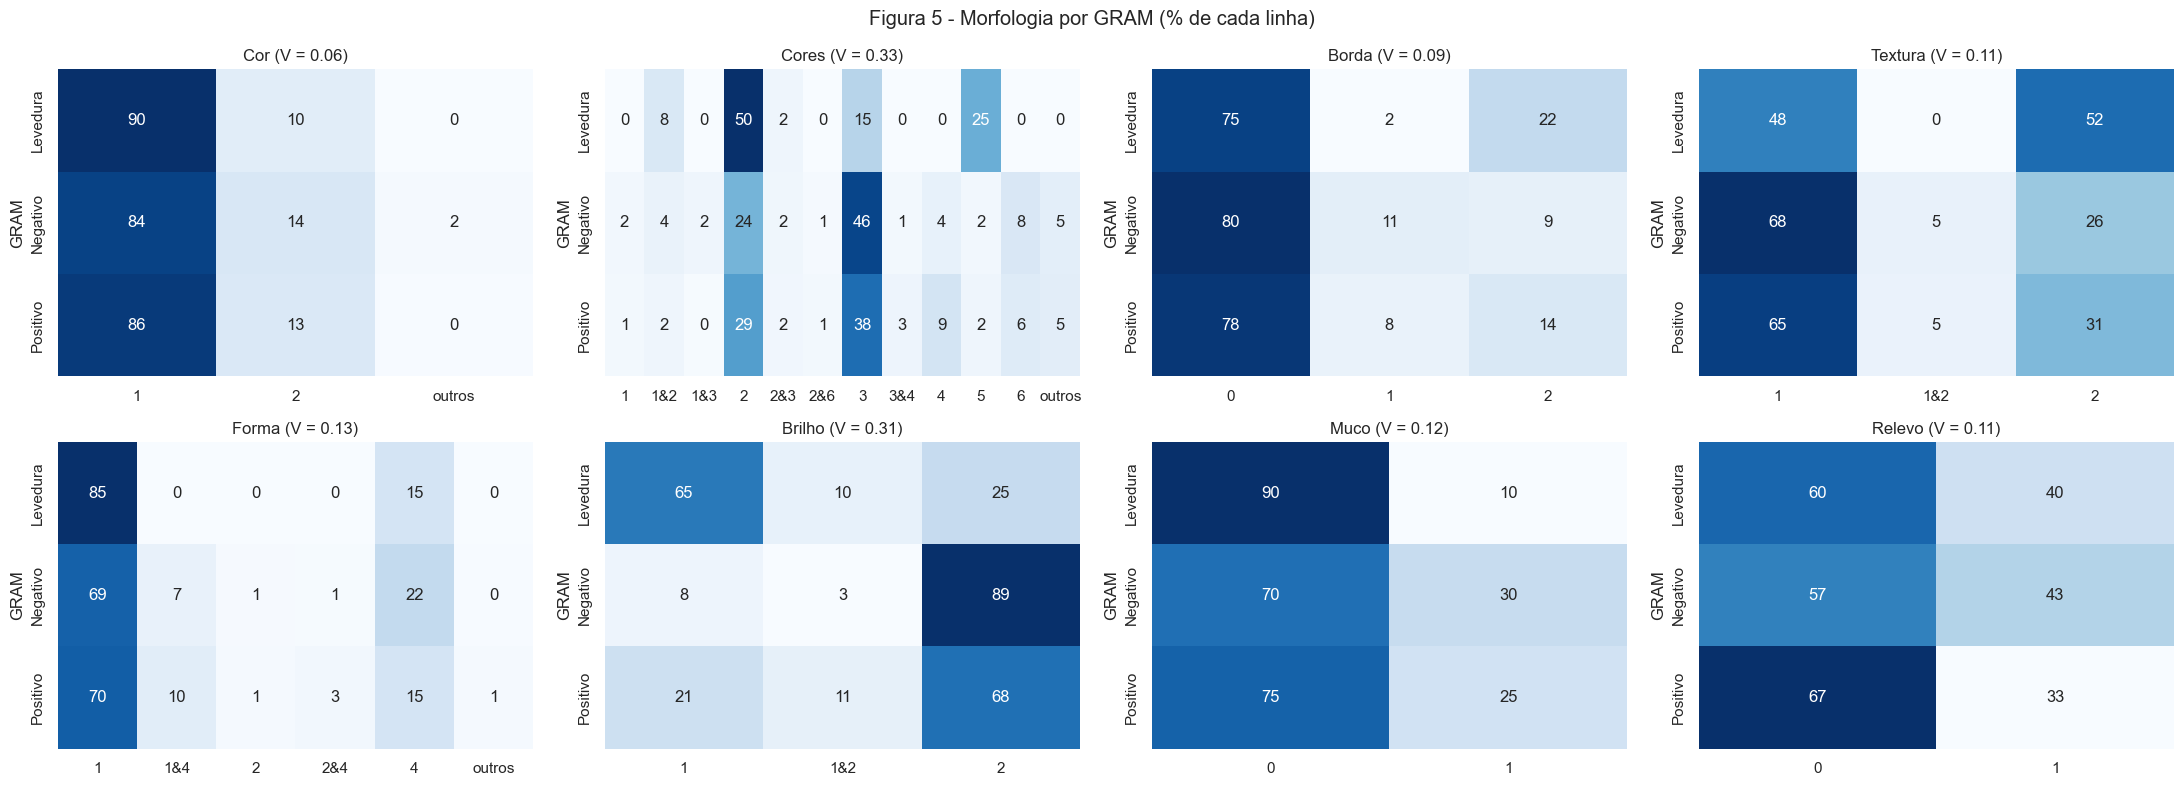

In [16]:
morph_str = df_clean[MORPH].apply(lambda col: col.map(lambda t: "&".join(str(c) for c in t)))  # tupla vira texto


def cramers_v(x, y):
    tab = pd.crosstab(x, y)
    chi2 = chi2_contingency(tab)[0]
    return np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))


tem_gram = df_clean["GRAM"].notna()
gram = df_clean.loc[tem_gram, "GRAM"]
v = pd.Series({c: cramers_v(gram, morph_str.loc[tem_gram, c]) for c in MORPH})
print(v.round(3))

fig, axes = plt.subplots(2, 4, figsize=(22, 8))
for ax, c in zip(axes.flat, MORPH):
    s = morph_str.loc[tem_gram, c]
    s = s.where(s.map(s.value_counts()) >= 5, "outros")  # codigos com menos de 5 isolados, so na figura
    tab = pd.crosstab(gram, s, normalize="index") * 100
    sns.heatmap(tab, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(f"{c} (V = {v[c]:.2f})")
    ax.set_xlabel("")
fig.suptitle("Figura 5 - Morfologia por GRAM (% de cada linha)")
plt.tight_layout()
plt.show()

Pelo V de Cramér, a morfologia tem pouca relação com o GRAM. Os maiores são Cores (0,327) e Brilho (0,307), e o resto fica abaixo de 0,13. Na Figura 5 dá para ver de onde vem isso: em Brilho, 89% dos Negativos têm código 2, enquanto 65% das Leveduras têm código 1, e em Cores metade das Leveduras tem a cor 2. Só que as Leveduras são só 40 isolados, então essas porcentagens mudam bastante com poucos casos.

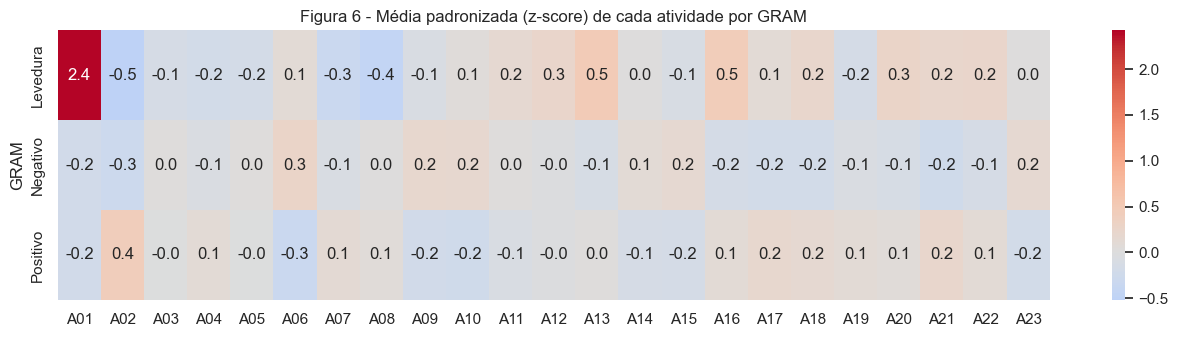

In [17]:
z = (df_clean[ACTS] - df_clean[ACTS].mean()) / df_clean[ACTS].std()  # z-score de cada atividade
media_gram = z[tem_gram].groupby(gram).mean()

plt.figure(figsize=(16, 3.5))
sns.heatmap(media_gram, annot=True, fmt=".1f", cmap="coolwarm", center=0, xticklabels=curtos)
plt.title("Figura 6 - Média padronizada (z-score) de cada atividade por GRAM")
plt.show()

Na Figura 6 a maioria das médias fica entre -0,3 e 0,3, ou seja, as atividades mudam pouco de um GRAM para outro. O destaque é a Atividade 01 nas Leveduras, com média 2,4 desvios acima da geral, o que sugere que essa atividade rara aparece mais nelas. As Leveduras também ficam um pouco acima na 13 e na 16 (0,5). Isso reforça que o GRAM não deve explicar muito dos grupos que vamos encontrar.

### 1.3 Transformações

Para o agrupamento e a redução usamos só as 23 atividades. A morfologia fica para caracterizar os grupos depois, o GRAM é só referência externa e o `n°` sai.

| Decisão | Escolha | Por quê |
|---|---|---|
| Cauda longa | `log1p` nas Atividades 06, 07, 14, 15 e 23 | têm assimetria acima de 2, e o `log1p` aceita o zero e os negativos pequenos |
| Escala | StandardScaler em tudo | K-Means, Ward e PCA usam distância e variância, e sem isso a 23 dominaria |
| Binárias | 0/1 e depois padronizadas | ficam na mesma escala das outras |
| Ordinais | números de 0 a 3 | a ordem dos níveis tem sentido |
| Morfologia | multi-hot (uma coluna 0/1 por código) | uma célula pode ter mais de um código e os códigos não são quantidades |

Uma coisa importante: padronizar binárias raras, como a 04, que tem só 19 positivos, faz cada positivo pesar bastante. Fizemos isso de propósito, porque para bioprospecção um isolado com uma atividade rara é justamente o que interessa. Na seção 4.1 testamos deixar as binárias sem padronizar.

In [18]:
LOG_COLS = [A(n) for n in [6, 7, 14, 15, 23]]


def preprocess(df_in, use_log=True, scaler="standard"):
    X = df_in[ACTS].astype(float)
    if use_log:
        X[LOG_COLS] = np.log1p(X[LOG_COLS])
    if scaler == "standard":
        sc = StandardScaler()
    else:
        sc = RobustScaler()
    Xs = pd.DataFrame(sc.fit_transform(X), columns=ACTS, index=X.index)
    return X, Xs  # sem escala e escalado


X_tr, Xs = preprocess(df_clean)
X = Xs.values


def multi_hot(df_in):
    M = pd.DataFrame(index=df_in.index)
    for col in MORPH:
        codigos = sorted(set(c for t in df_in[col] for c in t))
        for cod in codigos:
            M[f"{col}_{cod}"] = df_in[col].apply(lambda t: int(cod in t))  # 1 se o codigo aparece na celula
    return M


M = multi_hot(df_clean)
print(X.shape, M.shape)

(506, 23) (506, 29)


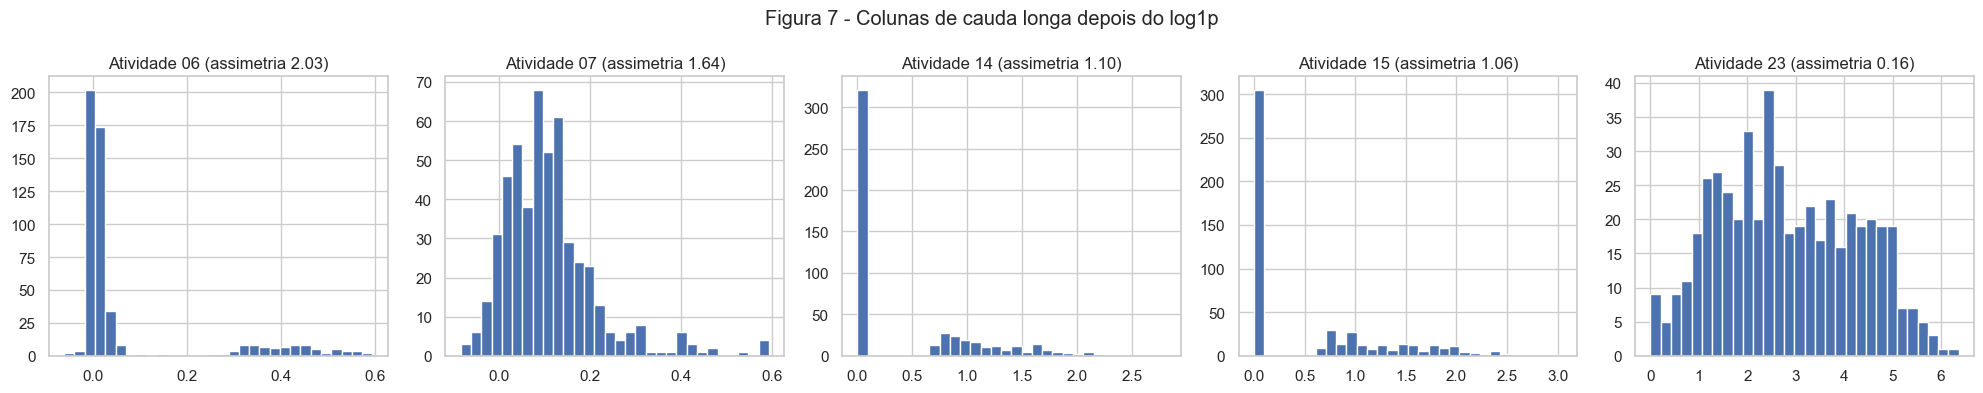

In [19]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, c in zip(axes, LOG_COLS):
    ax.hist(X_tr[c], bins=30)
    ax.set_title(f"{c} (assimetria {X_tr[c].skew():.2f})")
fig.suptitle("Figura 7 - Colunas de cauda longa depois do log1p")
plt.tight_layout()
plt.show()

Comparando a Figura 7 com a Figura 2, o log funcionou bem em algumas colunas e quase nada em outras. A 06 quase não mudou (de 2,14 para 2,03): os valores dela vão só até 0,81, e para números menores que 1 o `log1p` é quase uma reta, então a forma continua igual. Ela também continua bimodal, com um pico perto de zero e um grupo separado entre 0,3 e 0,6. A 07 mudou um pouco (de 2,24 para 1,64), pelo mesmo motivo.

A 14 e a 15 caíram para 1,10 e 1,06, mas o pico no zero continua, porque o log de zero é zero e mais de 60% dos isolados têm zero nelas. A 23 foi a que mais melhorou, de 3,14 para 0,16, e ficou quase simétrica.

## 2. Tarefa A - Agrupamento

Usamos o K-Means e o hierárquico aglomerativo com ligação de Ward. O K-Means escolhe k centros, coloca cada isolado no centro mais próximo e vai recalculando os centros até estabilizar. Ele precisa do k antes, prefere grupos redondos e de tamanho parecido e é sensível a valores extremos, porque o centro é uma média. O Ward começa com cada isolado sozinho e vai juntando os pares que menos aumentam a variância dentro dos grupos, formando um dendrograma que dá para cortar em qualquer k. Ele é determinístico, mas uma junção feita no começo nunca é desfeita.

Escolhemos essa dupla porque os dois usam distância euclidiana e preferem grupos compactos, então a comparação é justa, mas um reorganiza tudo a cada iteração e o outro não volta atrás. A ideia é ver onde eles concordam e onde discordam.

### 2.1 Escolha de k

Rodamos os dois para k de 2 a 10 e guardamos a inércia, a silhueta, o Davies-Bouldin e a estabilidade. A estabilidade é o ARI médio entre a partição com todos os dados e a partição refeita em 20 subamostras de 80%. Como o `AgglomerativeClustering` não dá a inércia, calculamos na mão.

In [20]:
def agrupa(alg, k, X):
    if alg == "K-Means":
        return KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(X)
    return AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)


def inercia(X, lab):
    return sum(((X[lab == g] - X[lab == g].mean(axis=0)) ** 2).sum() for g in np.unique(lab))  # soma dos quadrados dentro dos grupos


def estabilidade(alg, k, X, n_rep=20):
    rng = np.random.default_rng(SEED)
    cheio = agrupa(alg, k, X)
    aris = []
    for _ in range(n_rep):
        idx = rng.choice(len(X), size=int(0.8 * len(X)), replace=False)  # subamostra de 80% sem reposicao
        aris.append(adjusted_rand_score(cheio[idx], agrupa(alg, k, X[idx])))
    return np.mean(aris)


linhas = []
for k in range(2, 11):
    for alg in ["K-Means", "Ward"]:
        lab = agrupa(alg, k, X)
        linhas.append({"k": k, "alg": alg, "inercia": inercia(X, lab), "silhueta": silhouette_score(X, lab),
                       "davies_bouldin": davies_bouldin_score(X, lab), "estabilidade": estabilidade(alg, k, X)})

res_k = pd.DataFrame(linhas)
res_k.pivot(index="k", columns="alg").round(3)

inercia            silhueta        davies_bouldin        estabilidade  \
alg    K-Means       Ward  K-Means   Ward        K-Means   Ward      K-Means   
k                                                                              
2    10260.792  10499.419    0.119  0.115          2.609  2.734        0.926   
3     9335.027   9771.749    0.120  0.089          2.357  2.754        0.934   
4     8883.786   9221.378    0.124  0.105          2.142  2.380        0.781   
5     8386.006   8721.575    0.127  0.112          2.178  2.111        0.666   
6     7951.164   8228.864    0.137  0.124          2.064  2.009        0.688   
7     7488.981   7898.662    0.146  0.122          1.909  2.083        0.711   
8     7153.228   7597.198    0.139  0.111          1.942  2.088        0.786   
9     6974.419   7395.651    0.126  0.103          2.053  2.319        0.645   
10    6757.310   7200.130    0.132  0.096          2.011  2.261        0.632   

            
alg   Ward  
k           
2    0.455  
3    0.467  
4    0.452  
5    0.429  
6    0.452  
7    0.498  
8    0.502  
9    0.519  
10   0.493

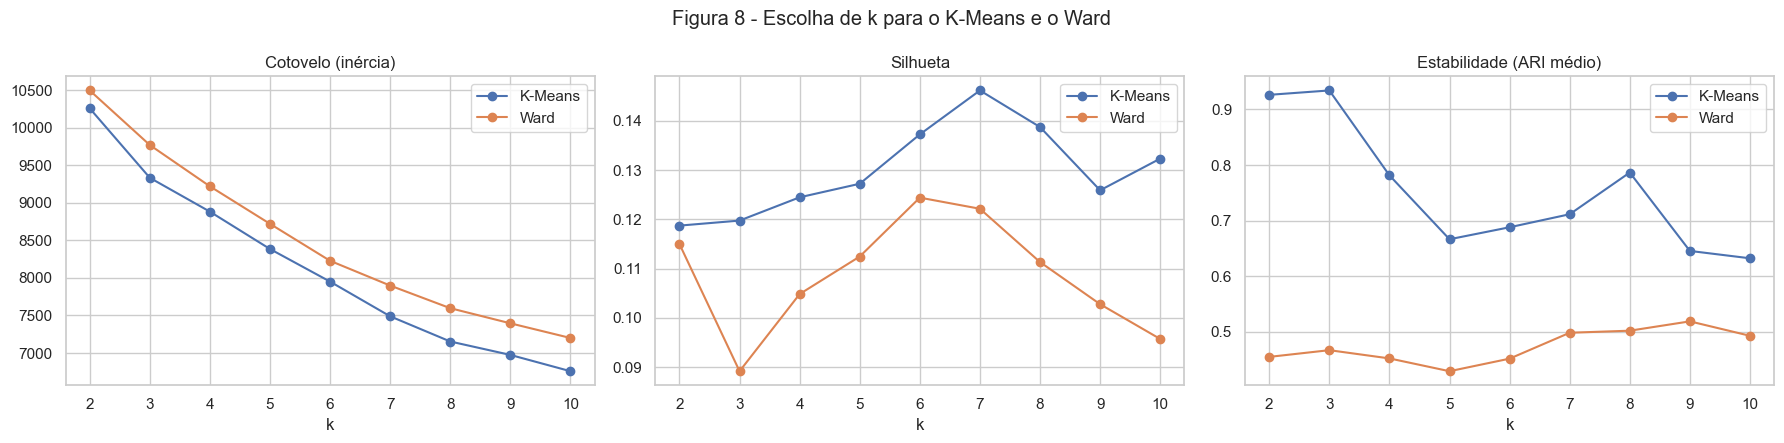

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, met, titulo in zip(axes, ["inercia", "silhueta", "estabilidade"], ["Cotovelo (inércia)", "Silhueta", "Estabilidade (ARI médio)"]):
    for alg in ["K-Means", "Ward"]:
        r = res_k[res_k["alg"] == alg]
        ax.plot(r["k"], r[met], marker="o", label=alg)
    ax.set_title(titulo)
    ax.set_xlabel("k")
    ax.legend()
fig.suptitle("Figura 8 - Escolha de k para o K-Means e o Ward")
plt.tight_layout()
plt.show()

Na Figura 8 a inércia cai sempre e não tem um cotovelo claro. A silhueta é baixa nos dois, no máximo 0,146 (K-Means com k = 7), o que mostra que os grupos não são muito separados. Na estabilidade o K-Means fica acima do Ward em todos os k, por exemplo 0,711 contra 0,498 em k = 7.

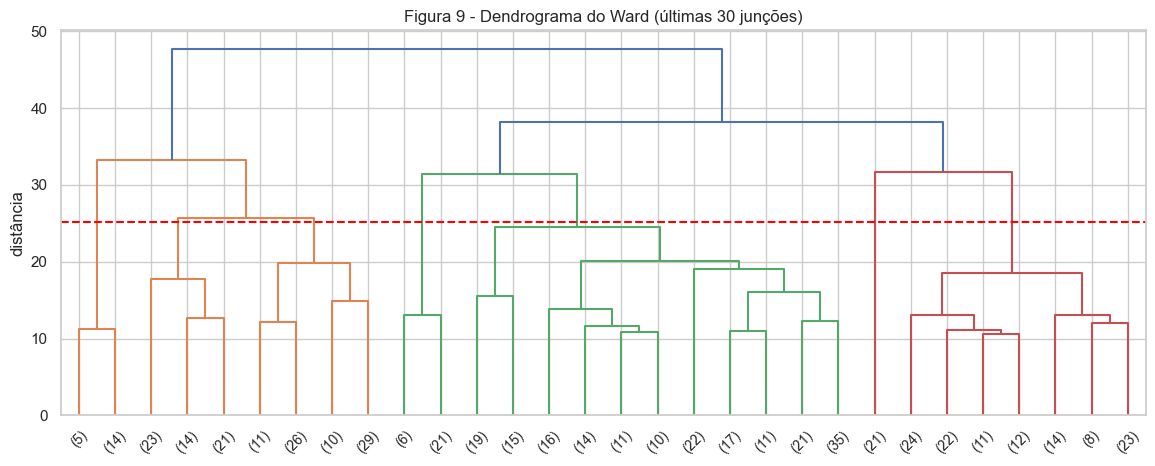

In [22]:
Z = linkage(X, method="ward")

plt.figure(figsize=(14, 5))
dendrogram(Z, truncate_mode="lastp", p=30)
plt.axhline((Z[-7, 2] + Z[-6, 2]) / 2, color="red", linestyle="--")  # altura do corte em 7 grupos
plt.title("Figura 9 - Dendrograma do Ward (últimas 30 junções)")
plt.ylabel("distância")
plt.show()

No dendrograma (Figura 9) a linha vermelha mostra o corte em 7 grupos. As junções mais altas, que separam 2 ou 3 grandes ramos, ficam bem acima das outras, mas o corte em 7 cai numa faixa onde as junções estão próximas umas das outras, então o próprio dendrograma não aponta um k claro.

Escolhemos k = 7 para os dois. É onde o K-Means tem a maior silhueta (0,146) e o menor Davies-Bouldin (1,909), e a estabilidade continua boa (0,711). Com k = 2 ou 3 o K-Means seria mais estável (0,926 e 0,934), mas a silhueta é menor e os grupos diriam pouco sobre perfis diferentes. Para o Ward o 7 não é o melhor em tudo (a silhueta em k = 6 é 0,124, quase igual aos 0,122 de k = 7), mas usamos o mesmo k para conseguir comparar os dois.

### 2.2 Avaliação

Rodamos os dois com k = 7 e renumeramos os grupos por tamanho (0 é o maior). O ARI e o NMI contra o GRAM usam só as linhas com GRAM, e a estabilidade aqui usa 30 subamostras.

In [23]:
K = 7


def renumera(lab):
    ordem = pd.Series(lab).value_counts().index  # do maior grupo para o menor
    return pd.Series(lab).map({g: i for i, g in enumerate(ordem)}).values


lab_km = renumera(agrupa("K-Means", K, X))
lab_hc = renumera(agrupa("Ward", K, X))

tg = tem_gram.values  # so as linhas com gram
aval = pd.DataFrame(index=["K-Means", "Ward"])
aval["silhueta"] = [silhouette_score(X, lab_km), silhouette_score(X, lab_hc)]
aval["davies_bouldin"] = [davies_bouldin_score(X, lab_km), davies_bouldin_score(X, lab_hc)]
aval["ARI GRAM"] = [adjusted_rand_score(gram, lab_km[tg]), adjusted_rand_score(gram, lab_hc[tg])]
aval["NMI GRAM"] = [normalized_mutual_info_score(gram, lab_km[tg]), normalized_mutual_info_score(gram, lab_hc[tg])]
aval["estabilidade"] = [estabilidade("K-Means", K, X, 30), estabilidade("Ward", K, X, 30)]
print("tamanhos K-Means:", np.bincount(lab_km))
print("tamanhos Ward:", np.bincount(lab_hc))
aval.round(3)

tamanhos K-Means: [134 123 111  71  27  21  19]
tamanhos Ward: [191 114  76  58  27  21  19]


,silhueta,davies_bouldin,ARI GRAM,NMI GRAM,estabilidade
K-Means,0.146,1.909,0.097,0.162,0.705
Ward,0.122,2.083,0.127,0.176,0.500


O K-Means sai melhor nas métricas internas: silhueta 0,146 contra 0,122, Davies-Bouldin 1,909 contra 2,083 e estabilidade 0,705 contra 0,5. Só que essas métricas premiam grupos compactos e redondos, que é justamente o que o K-Means procura, então não dá para usar só elas para dizer qual é melhor. E a silhueta é baixa nos dois, ou seja, os grupos existem, mas se sobrepõem bastante.

Contra o GRAM, o ARI fica em 0,097 no K-Means e 0,127 no Ward, e o NMI em 0,162 e 0,176. É bem baixo, mas isso não quer dizer que o agrupamento esteja errado: os grupos se formam pelas atividades, que mudam pouco com o tipo celular, como vimos na Figura 6.

### 2.3 Caracterização

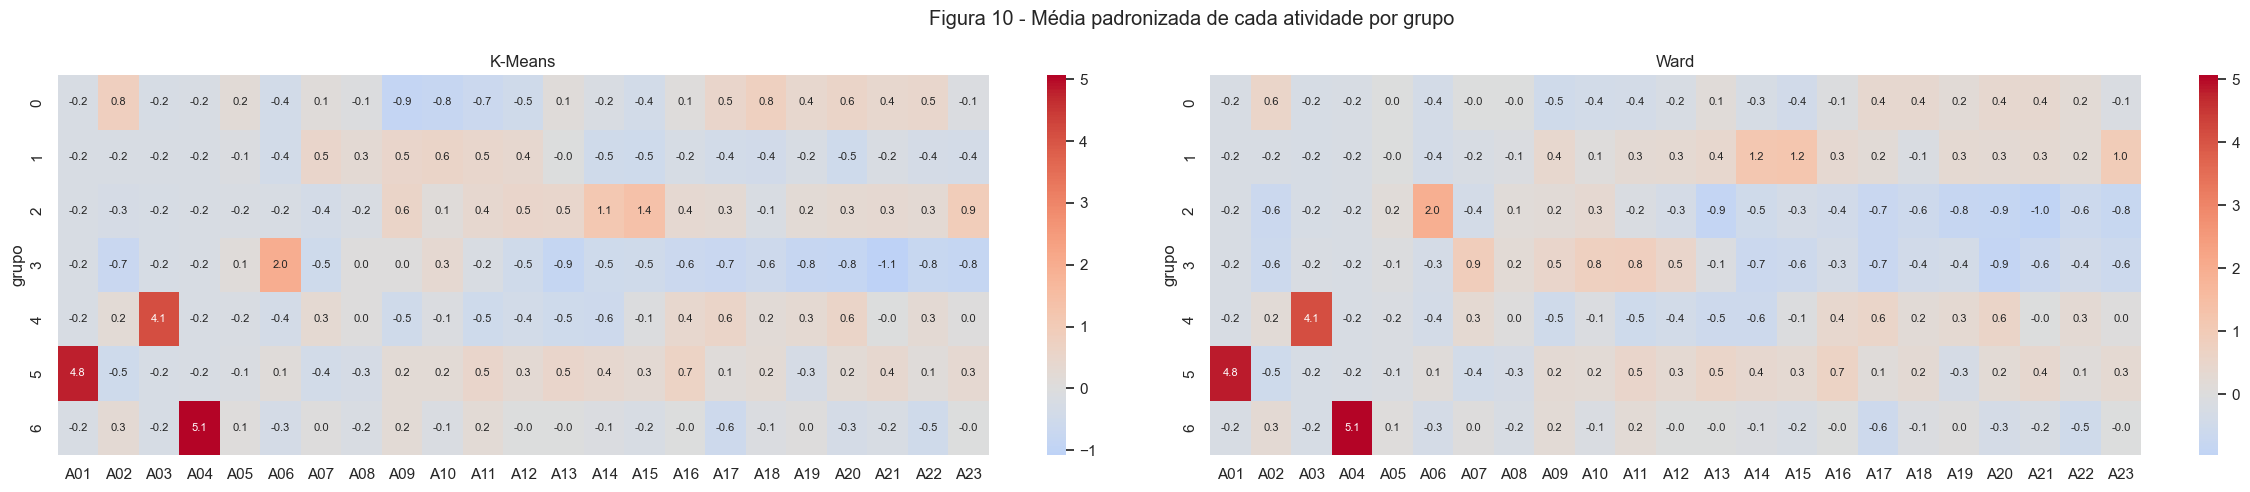

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(24, 5))
for ax, lab, nome in zip(axes, [lab_km, lab_hc], ["K-Means", "Ward"]):
    media = Xs.groupby(lab).mean()  # Xs ja esta padronizado, entao a media e um z-score
    sns.heatmap(media, annot=True, fmt=".1f", cmap="coolwarm", center=0, xticklabels=curtos, ax=ax, annot_kws={"size": 8})
    ax.set_title(nome)
    ax.set_ylabel("grupo")
fig.suptitle("Figura 10 - Média padronizada de cada atividade por grupo")
plt.tight_layout()
plt.show()

Na Figura 10, os grupos 4, 5 e 6 são iguais nos dois algoritmos, e cada um é marcado por uma binária rara: o 4 tem a Atividade 03 alta (4,1), o 5 tem a 01 (4,8) e o 6 tem a 04 (5,1). É o efeito que já esperávamos de padronizar binárias raras: os positivos ficam tão longe do resto que formam um grupo sozinhos.

Os quatro grupos maiores seguem os blocos de correlação da Figura 4: um com as ordinais e a A02 altas, um com o bloco 09-12 alto, um com a cauda longa (14, 15 e 23) alta e um com a A06 alta e as ordinais baixas.

In [25]:
def caracteriza(lab):
    t = morph_str.groupby(lab).agg(lambda s: s.value_counts().index[0])  # moda de cada coluna de morfologia
    t.insert(0, "tamanho", np.bincount(lab))
    pct = pd.crosstab(lab, df_clean["GRAM"], normalize="index") * 100
    return t.join(pct.round(0).add_prefix("% "))


print("K-Means")
display(caracteriza(lab_km))
print("Ward")
display(caracteriza(lab_hc))

K-Means


,tamanho,Cor,Cores,Borda,Textura,Forma,Brilho,Muco,Relevo,% Levedura,% Negativo,% Positivo
0,134,1,3,0,1,1,2,0,0,6.0,25.0,69.0
1,123,1,3,0,1,1,2,0,0,2.0,46.0,52.0
2,111,1,3,0,1,1,2,0,0,3.0,69.0,28.0
3,71,1,3,0,1,1,2,0,0,6.0,82.0,13.0
4,27,1,2,0,1,1,2,0,1,4.0,52.0,44.0
5,21,1,2,0,1,1,1,0,0,100.0,0.0,0.0
6,19,1,3,0,1,1,2,0,0,0.0,32.0,68.0


Ward


,tamanho,Cor,Cores,Borda,Textura,Forma,Brilho,Muco,Relevo,% Levedura,% Negativo,% Positivo
0,191,1,3,0,1,1,2,0,0,5.0,26.0,69.0
1,114,1,3,0,1,1,2,0,0,4.0,67.0,29.0
2,76,1,3,0,1,1,2,0,0,4.0,83.0,13.0
3,58,1,3,0,1,1,2,0,0,2.0,62.0,36.0
4,27,1,2,0,1,1,2,0,1,4.0,52.0,44.0
5,21,1,2,0,1,1,1,0,0,100.0,0.0,0.0
6,19,1,3,0,1,1,2,0,0,0.0,32.0,68.0


In [26]:
nomes_km = {0: "ordinais e A02 altas", 1: "bloco 09-12 alto", 2: "cauda longa alta (14, 15, 23)", 3: "A06 alta, ordinais baixas",
            4: "positivos da A03", 5: "positivos da A01", 6: "positivos da A04"}
nomes_hc = {0: "ordinais e A02 altas", 1: "cauda longa alta (14, 15, 23)", 2: "A06 alta, ordinais baixas", 3: "bloco 09-12 e A07 altos",
            4: "positivos da A03", 5: "positivos da A01", 6: "positivos da A04"}

pd.DataFrame({"K-Means": pd.Series(nomes_km), "n K-Means": np.bincount(lab_km),
              "Ward": pd.Series(nomes_hc), "n Ward": np.bincount(lab_hc)})

,K-Means,n K-Means,Ward,n Ward
0,ordinais e A02 altas,134,ordinais e A02 altas,191
1,bloco 09-12 alto,123,"cauda longa alta (14, 15, 23)",114
2,"cauda longa alta (14, 15, 23)",111,"A06 alta, ordinais baixas",76
3,"A06 alta, ordinais baixas",71,bloco 09-12 e A07 altos,58
4,positivos da A03,27,positivos da A03,27
5,positivos da A01,21,positivos da A01,21
6,positivos da A04,19,positivos da A04,19


Pela morfologia os grupos quase não se diferenciam: a moda é Cor 1, Cores 3, Borda 0, Textura 1, Forma 1 e Brilho 2 em quase todos, como já dava para esperar pela Figura 1. As exceções são o grupo dos positivos da A03, com Cores 2 e Relevo 1, e o dos positivos da A01, com Cores 2 e Brilho 1.

O GRAM separa um pouco mais. O grupo dos positivos da A01 tem 100% de Leveduras, o que explica o destaque da A01 nas Leveduras na Figura 6. O grupo de ordinais e A02 altas tem 69% de Positivos, e o de A06 alta tem 82% de Negativos no K-Means (83% no Ward). Para a priorização, os três grupos pequenos são os mais interessantes, porque juntam os isolados com uma atividade rara.

### 2.4 Comparação

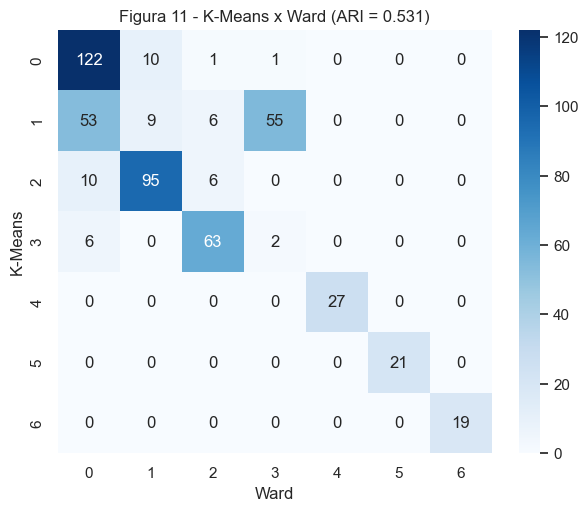

Os dois concordam em 79.4% dos isolados


In [27]:
ct = pd.crosstab(lab_km, lab_hc, rownames=["K-Means"], colnames=["Ward"])

plt.figure(figsize=(7, 5.5))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues")
plt.title(f"Figura 11 - K-Means x Ward (ARI = {adjusted_rand_score(lab_km, lab_hc):.3f})")
plt.show()

casa = ct.idxmax(axis=0)  # para cada grupo do ward, o grupo do k-means com mais isolados em comum
concorda = (pd.Series(lab_hc).map(casa).values == lab_km).mean()
print(f"Os dois concordam em {concorda:.1%} dos isolados")

Os dois concordam em 79,4% dos isolados, com ARI de 0,531 entre as partições. Os três grupos das binárias raras são idênticos (27, 21 e 19 isolados), porque esses isolados ficam muito longe de todo o resto e qualquer método os separa.

A discordância está nos grupos grandes. O grupo 1 do K-Means (bloco 09-12) foi dividido pelo Ward: 53 isolados foram para o grupo 0 e 55 para o grupo 3. Com isso, o grupo 0 do Ward ficou com 191 isolados, bem maior que qualquer grupo do K-Means. Isso combina com as premissas de cada um. O K-Means reajusta todas as atribuições a cada iteração e tende a fazer grupos de tamanho parecido. O Ward faz junções gulosas no começo que não desfaz depois, então, numa região onde a separação já é fraca (silhueta baixa), ele pode acabar juntando tudo num grupo grande.

## 3. Tarefa B - Redução de dimensionalidade

Usamos a PCA e a UMAP. A PCA é linear: ela procura combinações das atividades que concentram a maior variância possível, em ordem. Os eixos dá para interpretar pelos pesos de cada atividade, e dá para reconstruir os dados a partir de poucas componentes, mas ela supõe que as relações são lineares e que variância alta é informação. A UMAP é não linear: ela monta um grafo de vizinhos no espaço original e tenta montar um 2D em que os vizinhos continuem vizinhos. Ela preserva melhor a estrutura local, mas os eixos não significam nada e o resultado depende de `n_neighbors`, `min_dist` e da semente.

Escolhemos as duas justamente por isso: a PCA responde quais atividades variam juntas e a UMAP responde quem é parecido com quem. Se as duas contarem a mesma história, a estrutura é basicamente linear.

### 3.1 PCA

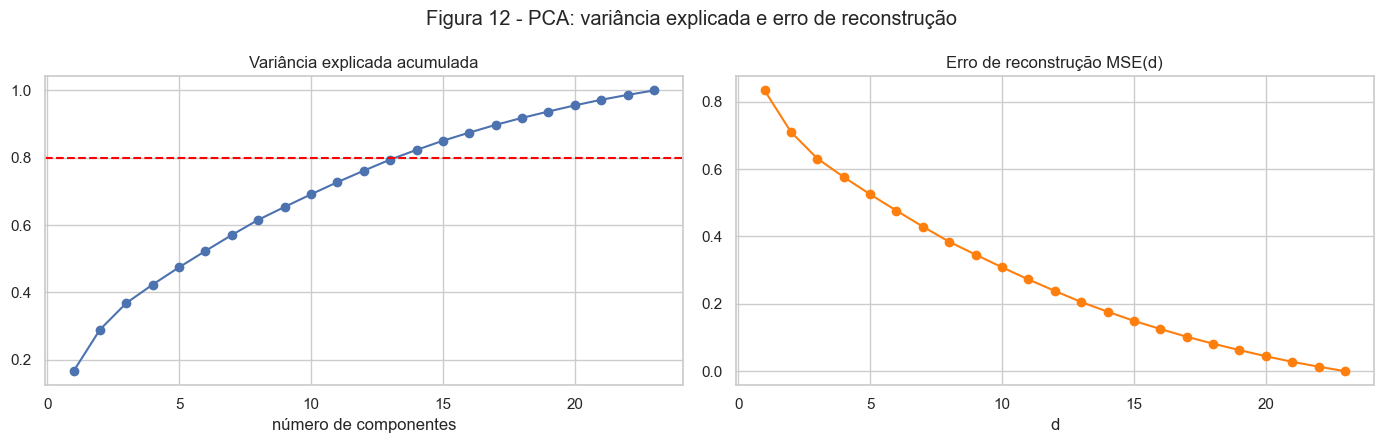

PC1 sozinha explica 16.6% e o MSE com d = 1 é 0.834
PC1 + PC2 explicam 29.0%
componentes para chegar a 80%: 14

PC1 - maiores pesos:
Atividade 20    0.349
Atividade 17    0.331
Atividade 22    0.328
Atividade 21    0.321
Atividade 18    0.302
dtype: float64

PC2 - maiores pesos:
Atividade 09    0.408
Atividade 11    0.385
Atividade 12    0.364
Atividade 15    0.344
Atividade 10    0.321
dtype: float64


In [28]:
pca = PCA(random_state=SEED).fit(X)
acum = np.cumsum(pca.explained_variance_ratio_)

mse = []
for d in range(1, 24):
    p = PCA(n_components=d, random_state=SEED).fit(X)
    X_rec = p.inverse_transform(p.transform(X))  # volta para as 23 dimensoes
    mse.append(np.mean((X - X_rec) ** 2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(range(1, 24), acum, marker="o")
axes[0].axhline(0.8, color="red", linestyle="--")
axes[0].set_title("Variância explicada acumulada")
axes[0].set_xlabel("número de componentes")
axes[1].plot(range(1, 24), mse, marker="o", color="tab:orange")
axes[1].set_title("Erro de reconstrução MSE(d)")
axes[1].set_xlabel("d")
fig.suptitle("Figura 12 - PCA: variância explicada e erro de reconstrução")
plt.tight_layout()
plt.show()

print(f"PC1 sozinha explica {acum[0]:.1%} e o MSE com d = 1 é {mse[0]:.3f}")
print(f"PC1 + PC2 explicam {acum[1]:.1%}")
print("componentes para chegar a 80%:", np.argmax(acum >= 0.8) + 1)
for i in range(2):
    pesos = pd.Series(pca.components_[i], index=ACTS)
    print(f"\nPC{i + 1} - maiores pesos:")
    print(pesos.reindex(pesos.abs().sort_values(ascending=False).index).head(5).round(3))

Pela Figura 12, cabe pouca informação em 2D: PC1 e PC2 juntas explicam só 29,0% da variância, e precisamos de 14 componentes para chegar a 80%. A curva sobe devagar, sem uma componente que domine, o que combina com a matriz de correlação da Figura 4, que tem blocos fracos.

Os dois primeiros eixos batem com os blocos que já tínhamos visto. A PC1 é o bloco das ordinais: os maiores pesos são das Atividades 20, 17, 22, 21 e 18, todos parecidos (entre 0,30 e 0,35). A PC2 é o bloco 09-12, com a 09, a 11 e a 12 na frente, junto com a 15.

A curva do MSE é o espelho da variância: como as colunas estão padronizadas, cada uma tem variância 1, então o erro de reconstrução com d componentes é exatamente a variância que ficou de fora. Em d = 1 o MSE é 0,834, que é 1 menos os 16,6% da PC1.

### 3.2 UMAP

Fazemos as duas projeções em 2D e testamos a estabilidade da UMAP rodando com `n_neighbors` 15 e 50 e sementes 0 e 1. Passamos `n_jobs=1` porque, com a semente fixa, a UMAP roda num processo só de qualquer jeito, e assim ela não fica avisando isso.

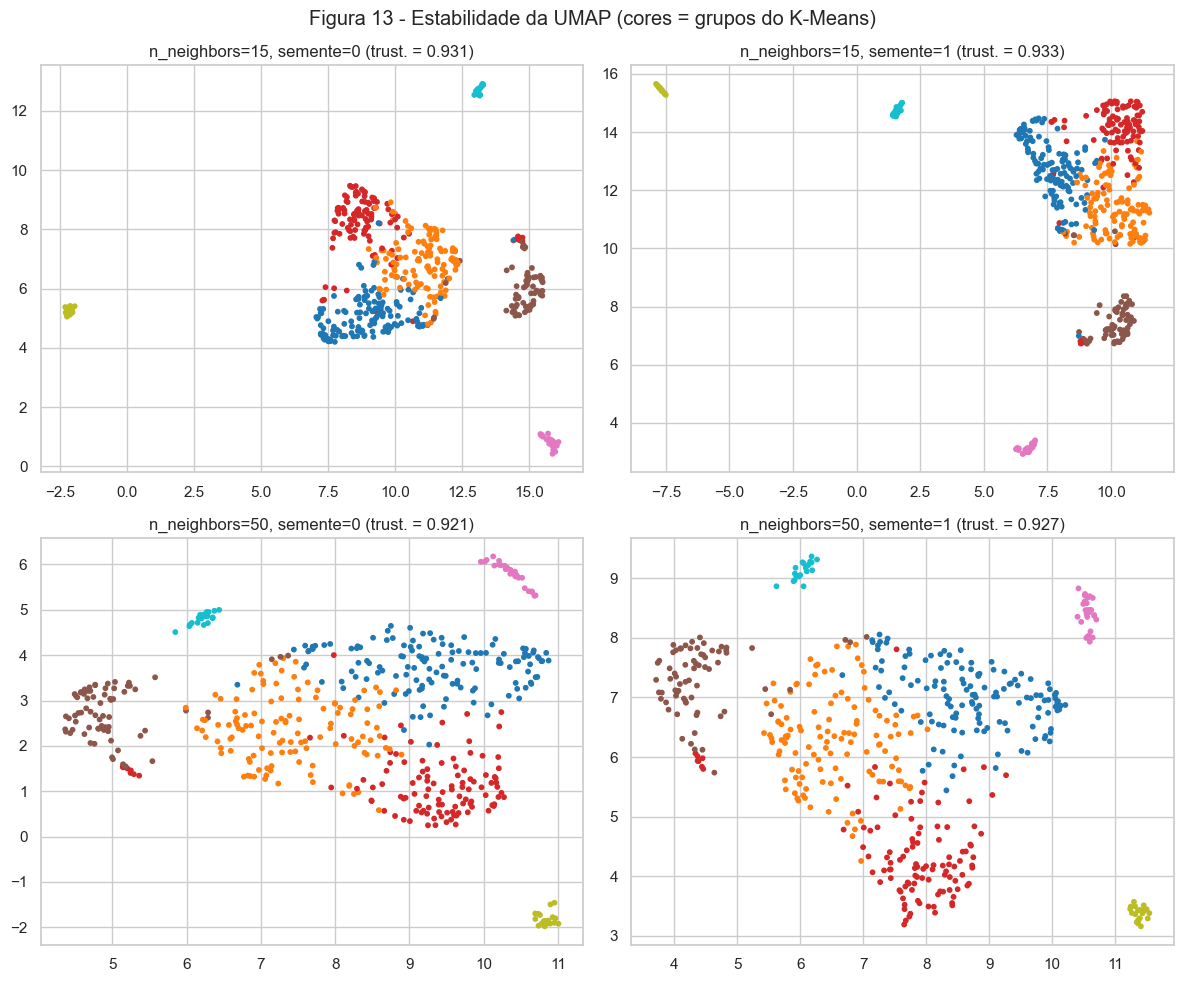

In [29]:
emb_pca = PCA(n_components=2, random_state=SEED).fit_transform(X)
emb_umap = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED, n_jobs=1).fit_transform(X)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for i, nn in enumerate([15, 50]):
    for j, semente in enumerate([0, 1]):
        e = umap.UMAP(n_neighbors=nn, min_dist=0.1, random_state=semente, n_jobs=1).fit_transform(X)
        tw = trustworthiness(X, e, n_neighbors=10)
        axes[i, j].scatter(e[:, 0], e[:, 1], c=lab_km, cmap="tab10", s=10)
        axes[i, j].set_title(f"n_neighbors={nn}, semente={semente} (trust. = {tw:.3f})")
fig.suptitle("Figura 13 - Estabilidade da UMAP (cores = grupos do K-Means)")
plt.tight_layout()
plt.show()

Na Figura 13, o que se mantém nas quatro execuções são as "ilhas": os grupos 4, 5 e 6 do K-Means (positivos das binárias raras) sempre aparecem bem separados do resto, e o grupo 3 (A06 alta) também fica à parte. Os grupos 0, 1 e 2 sempre formam uma massa só, com cada um ocupando uma região dela. O que muda é a posição, a rotação e a distância entre as ilhas, que dependem da semente, e com `n_neighbors=50` a massa principal fica mais espalhada e o grupo 3 encosta nela. A trustworthiness muda pouco, de 0,921 a 0,933, um pouco menor com 50 vizinhos. Ou seja, dá para confiar em quem está junto de quem, mas não na posição exata nem no tamanho dos espaços entre as ilhas.

### 3.3 Projeções

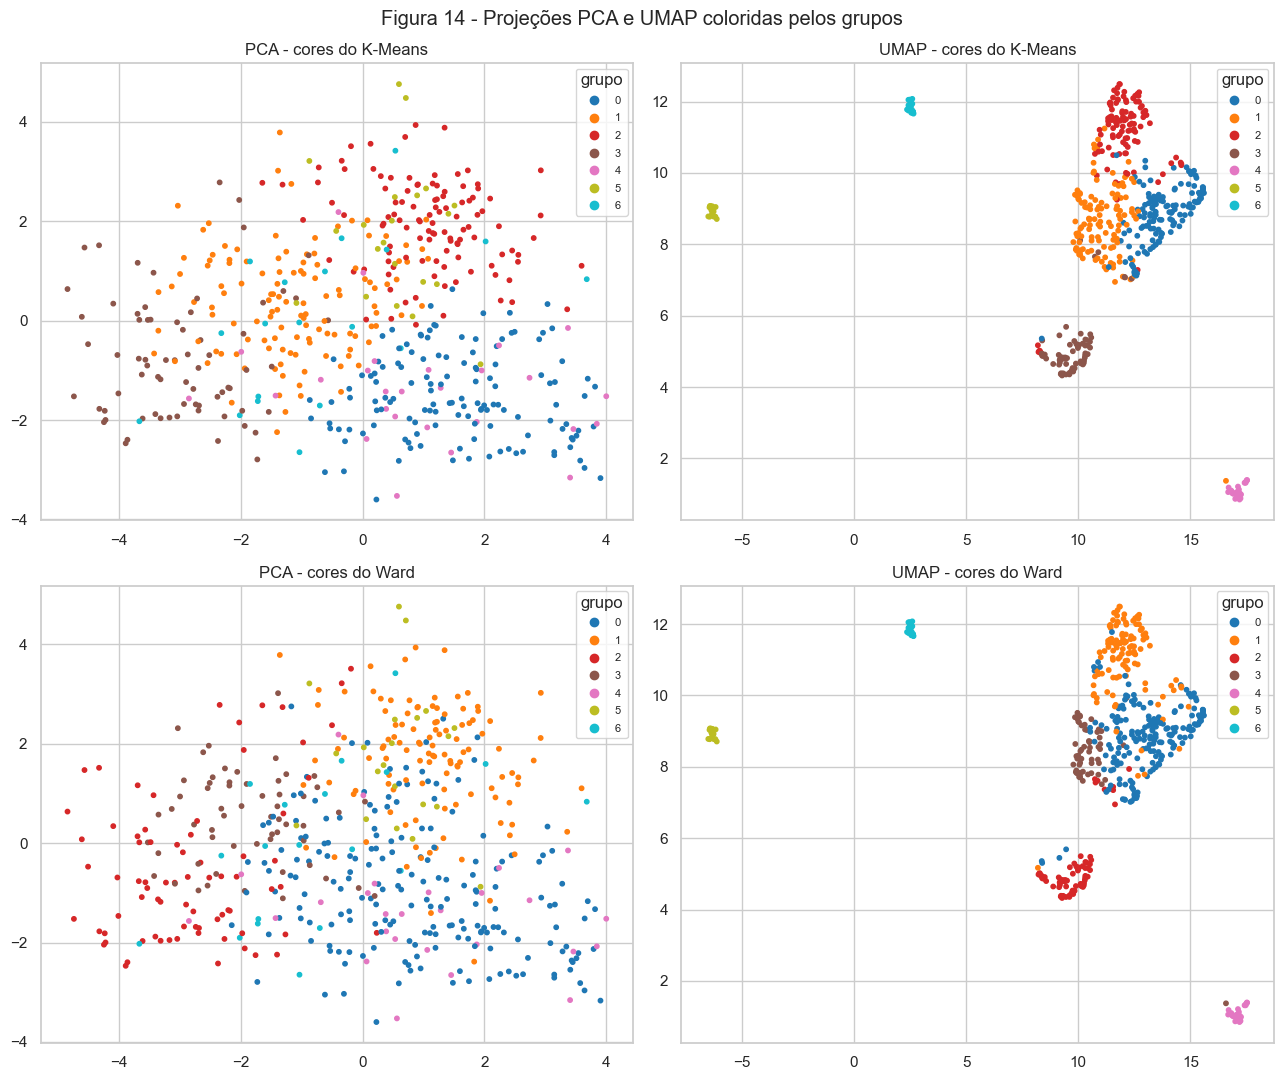

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for i, (lab, nome) in enumerate([(lab_km, "K-Means"), (lab_hc, "Ward")]):
    for j, (emb, proj) in enumerate([(emb_pca, "PCA"), (emb_umap, "UMAP")]):
        sc = axes[i, j].scatter(emb[:, 0], emb[:, 1], c=lab, cmap="tab10", s=10)
        axes[i, j].set_title(f"{proj} - cores do {nome}")
        axes[i, j].legend(*sc.legend_elements(), title="grupo", fontsize=8)
fig.suptitle("Figura 14 - Projeções PCA e UMAP coloridas pelos grupos")
plt.tight_layout()
plt.show()

As duas projeções não contam a mesma história. Na PCA (Figura 14, à esquerda) não aparece nenhum grupo separado: é uma nuvem só, onde os grupos grandes viram um degradê, com o grupo 0 do K-Means (ordinais altas) de um lado e o grupo 3 (A06 alta, ordinais baixas) do outro, como esperado já que a PC1 é o bloco das ordinais. Os três grupos das binárias raras somem no meio da nuvem, porque essas atividades quase não pesam nas duas primeiras componentes.

Na UMAP (à direita) esses mesmos três grupos viram ilhas bem separadas, e o grupo 3 também. Isso mostra que a parte mais forte da estrutura não é linear: são poucos isolados muito parecidos entre si e diferentes do resto, que a PCA não consegue mostrar em 2D. Pintando pelo Ward, dá para ver que o grupo 0 dele (191 isolados) se espalha por boa parte da massa principal da UMAP, enquanto no K-Means essa massa fica dividida em três regiões.

### 3.4 Avaliação

Medimos a trustworthiness das duas projeções (o quanto os vizinhos no 2D eram vizinhos de verdade no espaço original) e fazemos um teste de utilidade: um KNN com 7 vizinhos tentando prever o GRAM a partir de cada representação, com validação cruzada estratificada de 5 partes. Usamos a acurácia balanceada porque as Leveduras são poucas.

In [31]:
print(f"trustworthiness PCA:  {trustworthiness(X, emb_pca, n_neighbors=10):.3f}")
print(f"trustworthiness UMAP: {trustworthiness(X, emb_umap, n_neighbors=10):.3f}")

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
util = {}
for nome, rep in [("original (23D)", X), ("PCA 2D", emb_pca), ("UMAP 2D", emb_umap)]:
    modelo = make_pipeline(StandardScaler(), KNeighborsClassifier(7))
    util[nome] = cross_val_score(modelo, rep[tg], gram, cv=cv, scoring="balanced_accuracy").mean()  # so linhas com gram

pd.Series(util, name="acurácia balanceada").round(3).to_frame()

trustworthiness PCA:  0.765
trustworthiness UMAP: 0.932


,acurácia balanceada
original (23D),0.623
PCA 2D,0.455
UMAP 2D,0.617


A UMAP preserva bem melhor os vizinhos: trustworthiness de 0,932 contra 0,765 da PCA. No teste com o KNN, a UMAP 2D chega a 0,617 de acurácia balanceada, quase igual aos dados originais (0,623), enquanto a PCA 2D cai para 0,455. Os três ficam acima do chute (um terço, com três classes), mas nenhum é muito bom, o que de novo mostra que o GRAM não é o que mais organiza as atividades.

Na prática, cada método serve para uma coisa. A PCA serve para entender os eixos, ou seja, quais ensaios variam juntos (as ordinais na PC1 e o bloco 09-12 na PC2), mas em 2D ela deixa de fora cerca de 71% da variância e esconde os grupos pequenos. A UMAP serve para visualizar e encontrar grupos, principalmente os isolados com atividades raras, que são os mais interessantes para priorizar. Só que os eixos dela não significam nada, e as distâncias entre as ilhas não devem ser interpretadas.

## 4. Análise crítica

### 4.1 Sensibilidade ao pré-processamento

Refizemos o K-Means da Tarefa A trocando uma decisão de cada vez: sem o log, com RobustScaler, sem as duas linhas do 1551 e com as binárias de volta em 0/1, sem padronizar. Para cada variação procuramos o k de melhor silhueta (de 2 a 10) e comparamos a nova partição com a principal (`lab_km`) pelo ARI, usando as mesmas linhas. Como o k muda em algumas variações, também mostramos o ARI com k = 7, para separar o efeito de mudar o k do efeito de mudar os grupos.

In [32]:
def melhor_k(Xv):
    sil = {k: silhouette_score(Xv, agrupa("K-Means", k, Xv)) for k in range(2, 11)}
    k = max(sil, key=sil.get)
    return k, sil[k]


todas = np.ones(len(X), dtype=bool)
sem_rep = ~df_clean[ID].str.startswith("1551").values  # tira o 1551_a e o 1551_b

_, Xs_semlog = preprocess(df_clean, use_log=False)
_, Xs_rob = preprocess(df_clean, scaler="robust")
_, Xs_semrep = preprocess(df_clean[sem_rep])
Xs_bin = Xs.copy()
Xs_bin[BIN_ACTS] = df_clean[BIN_ACTS].values  # binarias voltam para 0/1

variacoes = {"principal": (X, todas), "sem log": (Xs_semlog.values, todas), "RobustScaler": (Xs_rob.values, todas),
             "sem o 1551": (Xs_semrep.values, sem_rep), "binárias 0/1": (Xs_bin.values, todas)}

sens = []
for nome, (Xv, linhas) in variacoes.items():
    k, sil = melhor_k(Xv)
    sens.append({"variação": nome, "melhor k": k, "silhueta": sil,
                 "ARI vs lab_km": adjusted_rand_score(lab_km[linhas], agrupa("K-Means", k, Xv)),
                 "ARI com k = 7": adjusted_rand_score(lab_km[linhas], agrupa("K-Means", K, Xv))})

pd.DataFrame(sens).set_index("variação").round(3)

,melhor k,silhueta,ARI vs lab_km,ARI com k = 7
variação,,,,
principal,7,0.146,1.000,1.000
sem log,8,0.134,0.602,0.501
RobustScaler,2,0.771,0.128,0.296
sem o 1551,7,0.146,0.916,0.916
binárias 0/1,2,0.134,0.235,0.389


In [33]:
iqr = X_tr.quantile(0.75) - X_tr.quantile(0.25)  # o robustscaler divide por isso
print("menores IQR antes de escalar:")
print(iqr.sort_values().head(5).round(3))
print("\nmaiores desvios padrão depois do RobustScaler:")
print(Xs_rob.std().sort_values(ascending=False).head(3).round(2))

lab_rob = agrupa("K-Means", 2, Xs_rob.values)
print("\ntamanhos com RobustScaler e k = 2:", np.bincount(lab_rob))
print("mediana da Atividade 06 (valor original) em cada grupo:", df_clean.groupby(lab_rob)[A(6)].median().round(2).to_dict())

lab_bin7 = renumera(agrupa("K-Means", K, Xs_bin.values))
pd.crosstab(lab_km, lab_bin7, rownames=["principal"], colnames=["binárias 0/1, k = 7"])

menores IQR antes de escalar:
Atividade 01    0.00
Atividade 03    0.00
Atividade 04    0.00
Atividade 06    0.02
Atividade 08    0.04
dtype: float64

maiores desvios padrão depois do RobustScaler:
Atividade 06    7.74
Atividade 18    1.10
Atividade 22    0.97
dtype: float64

tamanhos com RobustScaler e k = 2: [426  80]
mediana da Atividade 06 (valor original) em cada grupo: {0: 0.01, 1: 0.5}


"binárias 0/1, k = 7",0,1,2,3,4,5,6
principal,,,,,,,
0,0,33,0,49,0,52,0
1,0,29,36,10,0,0,48
2,81,2,24,2,0,1,1
3,0,6,2,0,63,0,0
4,0,7,1,9,1,7,2
5,5,3,10,0,1,2,0
6,3,7,3,2,1,2,1


A decisão que mais mudou o resultado foi deixar as binárias em 0/1. O melhor k caiu para 2, e o ARI com a partição principal ficou em 0,235 (0,389 mesmo forçando k = 7). Na tabela cruzada dá para ver o motivo: os três grupos das binárias raras (linhas 4, 5 e 6) se espalham pelos outros grupos, porque sem padronizar um positivo vale só 1 e deixa de pesar mais que as outras atividades. Dos grupos grandes, o 2 (cauda longa) e o 3 (A06 alta) quase não mudam (81 de 111 e 63 de 71 continuam juntos), mas o 0 e o 1 se reorganizam. Ou seja, os três grupos pequenos da Tarefa A existem por causa da nossa decisão de padronizar as binárias. Isso ajuda a destacar os isolados com atividade rara, que é o que queríamos, mas não é uma estrutura que aparece sozinha nos dados.

O RobustScaler deu a silhueta mais alta de todas (0,771 com k = 2), o que parece bom mas é um problema. Ele divide cada coluna pelo IQR, e a Atividade 06 tem IQR de só 0,02, porque a maioria dos isolados tem valor perto de zero. Com isso, depois de escalar, o desvio padrão dela vai para 7,74, enquanto o segundo maior fica em 1,10. A distância passa a ser praticamente só a Atividade 06, e os dois grupos são os 426 isolados com a 06 perto de zero (mediana 0,01) e os 80 do segundo pico (mediana 0,5), que já tínhamos visto na Figura 2. Já as binárias raras têm IQR 0, e nesse caso o sklearn não divide, então elas ficam quase sem peso. A silhueta alta só mostra que uma coluna dominou, e não que os grupos ficaram melhores.

Tirar o log mudou o resultado de forma moderada (k = 8 e ARI de 0,602), e tirar as duas linhas do 1551 quase não mudou nada (ARI de 0,916, com o mesmo k = 7). Então a decisão de manter as duas linhas não afeta as conclusões.

### 4.2 Conclusões e limitações

Na exploração e na limpeza, encontramos os cinco tipos de problema que o enunciado avisava, e o log terminou com 33 correções. As 23 atividades se organizam em três blocos fracos de correlação (09 a 12, as ordinais de 17 a 22 e as de cauda longa 14, 15 e 23), e quase nada disso tem a ver com o GRAM ou com a morfologia. No agrupamento, os dois algoritmos concordaram em 79,4% dos isolados e acharam quatro perfis grandes, que seguem esses blocos, e três grupos pequenos formados pelos positivos das binárias raras 03, 01 e 04, sendo que o da 01 é todo de Leveduras. Na redução, a PCA mostrou que os eixos principais são o bloco das ordinais e o 09-12, e a UMAP mostrou os grupos raros como ilhas separadas. Para o Regenera, a sugestão prática é olhar primeiro para os 67 isolados desses três grupos pequenos, que são os que têm atividades raras, e usar os blocos para entender quais ensaios costumam responder juntos. Como nenhuma correlação passa de 0,7, não dá para cortar ensaios só com base nisso.

Os resultados têm limites bem concretos. Os três grupos mais interessantes têm só 27, 21 e 19 isolados e, como vimos na 4.1, dependem da padronização das binárias. A silhueta com k = 7 é só 0,146, a estabilidade é 0,705 no K-Means e 0,5 no Ward, e o melhor k muda de 7 para 2 ou 8 dependendo do pré-processamento. As figuras 2D da PCA deixam de fora cerca de 71% da variância, e a UMAP preserva bem os vizinhos (trustworthiness de 0,932), mas não as distâncias globais, então o espaço entre as ilhas não quer dizer nada. As Atividades 20 e 21 tiveram 27 e 17 valores preenchidos pela moda, e elas estão entre os maiores pesos da PC1 (0,349 e 0,321), então a imputação pode ter puxado um pouco esse eixo. As métricas internas favorecem grupos compactos e redondos, o que dá vantagem ao K-Means na comparação. E, como os ensaios são anonimizados, não conseguimos dizer o que cada grupo significa biologicamente, só que os isolados de um mesmo grupo respondem de forma parecida.

A maior dificuldade foi não ter gabarito. Em quase todas as etapas tivemos que decidir sem saber se estava certo, desde tratar o "20" em Cores como erro até escolher o k com uma silhueta baixa e um dendrograma que não ajudava muito. Também demoramos para perceber que os grupos pequenos vinham da padronização das binárias, e foi a análise de sensibilidade que deixou isso claro. Interpretar a UMAP também deu trabalho, porque a figura muda com a semente e com o `n_neighbors`, e tivemos que aprender a olhar para quem fica junto de quem, e não para a posição dos pontos. Por fim, garantir que todos os números do texto batessem com as saídas exigiu rodar o notebook inteiro várias vezes.